# Bayesian logistic regression with the Laplace approximation

Logistic regression models a binary label through a linear log-odds function. A Gaussian prior defines a posterior over the coefficients, and the Laplace approximation represents its local shape by a Gaussian.

## Setup

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit, log_expit, logsumexp, roots_hermitenorm
from scipy.integrate import trapezoid
from scipy.stats import norm
from IPython.display import display, Markdown

# Limit BLAS threading when threadpoolctl is available.
try:
    from threadpoolctl import threadpool_limits
    _blas_limit = threadpool_limits(limits=1)
except ImportError:
    _blas_limit = None

MC_SAMPLES = 4096
completed = set()
np.set_printoptions(precision=5, suppress=True)

In [6]:
def table(headers, rows, digits=5):
    """Display a table of numerical results."""
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return format(value, ".{}g".format(digits))
        return str(value)
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def check_exercise(number, test):
    """Run tests, skipping an explicitly unfinished implementation."""
    completed.discard(number)
    try:
        test()
    except NotImplementedError:
        print(f"Exercise {number}: unfinished.")
        return False
    completed.add(number)
    print(f"Exercise {number}: checks passed.")
    return True

def ready(*numbers):
    missing = [number for number in numbers if number not in completed]
    if missing:
        labels = [f"Exercise {number}" for number in missing]
        print("Complete " + ", ".join(labels) + " to evaluate this example.")
        return False
    return True

def fd_gradient(fun, point, h=1e-5):
    """Central finite differences for a small diagnostic problem."""
    point = np.asarray(point, dtype=float)
    eye = np.eye(len(point))
    return np.array([(fun(point + h*e) - fun(point - h*e))/(2*h) for e in eye])

def fd_jacobian(fun, point, h=1e-5):
    point = np.asarray(point, dtype=float)
    eye = np.eye(len(point))
    return np.column_stack([(fun(point + h*e) - fun(point - h*e))/(2*h) for e in eye])

## 1. Logistic regression

### 1.1 Data, parameter, and likelihood

Let $\mathcal D=\{(x_i,y_i)\}_{i=1}^{n}$, where $x_i\in\mathbb R^d$ and
$y_i\in\{0,1\}$. The design matrix $X\in\mathbb R^{n\times d}$ has rows $x_i^\top$;
$y=(y_1,\ldots,y_n)^\top$. The coefficient vector is $\theta\in\mathbb R^d$.
An intercept is included by setting the first component of each $x_i$ to one.
We condition on $X$; we do not model its distribution.

Logistic regression assumes linear log odds:

$$
\log\frac{p_i}{1-p_i}=x_i^\top\theta=:a_i,
\qquad
p_i=p(y_i=1\mid x_i,\theta)=\sigma(a_i),
\qquad
\sigma(a)=\frac{1}{1+e^{-a}}.
$$

Conditional independence of the labels gives the Bernoulli likelihood

$$
p(y\mid X,\theta)=\prod_{i=1}^{n}p_i^{y_i}(1-p_i)^{1-y_i}.
$$

Taking logarithms yields

$$
\ell_{\mathrm{lik}}(\theta)
=\sum_i\big[y_i\log\sigma(a_i)+(1-y_i)\log\sigma(-a_i)\big]
=y^\top X\theta-\sum_i\log(1+e^{a_i}).
$$

The identity $1-\sigma(a)=\sigma(-a)$ lets us use the sigmoid for both labels.
In code, `expit(a)` evaluates $\sigma(a)$ and `log_expit(a)` evaluates
$\log\sigma(a)$ directly. The latter avoids taking the logarithm of a probability
that has rounded to zero [6].

### 1.2 A small dataset

Write $x_i=(1,u_i)^\top$ with a scalar covariate $u_i$.
Generate 24 observations with generating coefficient
$\theta_{\mathrm{gen}}=(-0.6,1.4)^\top$. The generating coefficient is known only
because this is a simulation; it is not an input to inference.

In [7]:
def sigmoid(a):
    """Logistic sigmoid, evaluated stably for scalars or arrays."""
    return expit(np.asarray(a, dtype=float))

check_logits = np.array([[-2.0, 0.0, 2.0], [0.5, -0.5, 1.0]])
np.testing.assert_allclose(sigmoid(check_logits),
                           1.0 / (1.0 + np.exp(-check_logits)))
np.testing.assert_allclose(sigmoid(np.array([-1000.0, 0.0, 1000.0])),
                           [0.0, 0.5, 1.0])

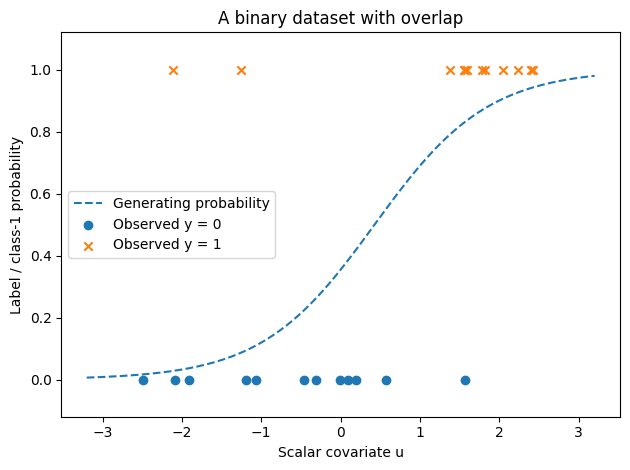

n = 24, d = 2, positive labels = 12


In [8]:
rng = np.random.default_rng(13)
u = np.sort(rng.uniform(-2.5, 2.5, size=24))
X = np.column_stack([np.ones_like(u), u])
theta_gen = np.array([-0.6, 1.4])
y = rng.binomial(1, sigmoid(X @ theta_gen)).astype(float)
n, d = X.shape
m0 = np.zeros(d)
S0 = 2.5**2 * np.eye(d)
P0 = np.eye(d) / 2.5**2

u_plot = np.linspace(-3.2, 3.2, 250)
fig, ax = plt.subplots()
for label, marker in [(0, "o"), (1, "x")]:
    keep = y == label
    ax.scatter(u[keep], y[keep], marker=marker, label="Observed y = {}".format(label))
ax.plot(u_plot, sigmoid(theta_gen[0] + theta_gen[1]*u_plot),
        linestyle="--", label="Generating probability")
ax.set(xlabel="Scalar covariate u", ylabel="Label / class-1 probability",
       title="A binary dataset with overlap", ylim=(-0.12, 1.12))
ax.legend(loc="center left")
fig.tight_layout()
plt.show()
print("n = {}, d = {}, positive labels = {}".format(n, d, int(y.sum())))

### 1.3 Score and curvature

Differentiate the sigmoid directly:

$$
\sigma'(a)=\frac{e^{-a}}{(1+e^{-a})^2}
=\sigma(a)\,[1-\sigma(a)].
$$

For one observation, the derivative of $y_i a_i-\log(1+e^{a_i})$ with respect to
$a_i$ is $y_i-p_i$. Because $\nabla_\theta a_i=x_i$, the chain rule gives

$$
\nabla_\theta\ell_{\mathrm{lik}}(\theta)
=\sum_i x_i(y_i-p_i)=X^\top(y-p),
\qquad p=\sigma(X\theta)\in\mathbb R^n.
$$

A second derivative gives

$$
\nabla_\theta^2\ell_{\mathrm{lik}}(\theta)
=-\sum_i p_i(1-p_i)x_ix_i^\top=-X^\top W X,
\qquad W=\operatorname{diag}\big(p_i(1-p_i)\big)\in\mathbb R^{n\times n}.
$$

For every $v\in\mathbb R^d$,

$$
v^\top X^\top W Xv=\sum_i p_i(1-p_i)(x_i^\top v)^2\geq0.
$$

Thus the log likelihood is concave. At finite coefficients every $p_i(1-p_i)>0$,
but the matrix can still be singular if $X$ lacks column rank. The scalar weight
$p_i(1-p_i)$ is largest at $p_i=1/2$; the total contribution also depends on the size
and direction of $x_i$. A large scalar weight alone does not identify the most
informative observation in every parameter direction.

When can the likelihood Hessian be singular? How does the feature direction affect an observation’s contribution to curvature?

## 2. Gaussian prior and MAP estimation

Let the prior be $\theta\sim\mathcal N(m_0,S_0)$, where
$m_0\in\mathbb R^d$ and the covariance $S_0\in\mathbb R^{d\times d}$ is symmetric
positive definite. Write $P_0=S_0^{-1}$ to abbreviate the inverse prior covariance. Up to an additive constant independent of $\theta$, the log prior is

$$
\log p(\theta)=C-\tfrac12(\theta-m_0)^\top P_0(\theta-m_0).
$$

Bayes' rule is

$$
p(\theta\mid\mathcal D)=\frac{p(y\mid X,\theta)p(\theta)}{Z},
\qquad Z=p(y\mid X)=\int_{\mathbb R^d}p(y\mid X,\theta)p(\theta)\,d\theta.
$$

The Gaussian log prior is quadratic, but the log likelihood is not.
Therefore this Gaussian family is not conjugate to the logistic likelihood; the
posterior is not generally Gaussian and $Z$ is not generally an analytic integral.

Define the negative log posterior up to an additive constant by

$$
J(\theta)=-\sum_i\big[y_i\log\sigma(a_i)+(1-y_i)\log\sigma(-a_i)\big]
+\tfrac12(\theta-m_0)^\top P_0(\theta-m_0).
$$

Its gradient $g(\theta)\in\mathbb R^d$ and Hessian
$H(\theta)\in\mathbb R^{d\times d}$ follow by changing the likelihood signs and
differentiating the quadratic prior:

$$
g(\theta)=X^\top(p-y)+P_0(\theta-m_0),\qquad
H(\theta)=X^\top W X+P_0.
$$

For nonzero $v$, $v^\top H(\theta)v\geq v^\top P_0v>0$.
The objective is strongly convex. In addition, its nonnegative likelihood term and
positive-definite quadratic prior imply $J(\theta)\to\infty$ as
$\|\theta\|\to\infty$. Continuity therefore guarantees a minimizer; strict
convexity makes it unique. This is $\theta_{\mathrm{MAP}}$.
The posterior is proper because $0<p(y\mid X,\theta)\leq1$ and the prior is proper.

With $m_0=0$ and $P_0=\alpha I_d$, $\alpha>0$, the penalty is
$\alpha\|\theta\|^2/2$. This is the exact MAP interpretation of an L2 penalty
with this objective scaling and with the intercept penalized as specified.

We use the summed log likelihood throughout. Dividing the objective by $n$ leaves its minimizer unchanged but divides its Hessian by $n$. Use the summed-objective Hessian in the Laplace covariance.

### Exercise 1 — Negative log posterior

Implement `binary_terms(theta, X, y, m0, P0)`. Return the scalar $J$, its gradient
$g\in\mathbb R^d$, and its Hessian $H\in\mathbb R^{d\times d}$.
Use `sigmoid(a)` for the probabilities and
`log_expit(a)`, `log_expit(-a)` for the two log-probability terms.

Compute the summed negative log likelihood and add the Gaussian prior penalty.
For the Hessian, use a weighted matrix product rather than constructing the
$n\times n$ matrix $W$. The weights can be evaluated as
`sigmoid(a) * sigmoid(-a)`, which equals $p_i(1-p_i)$.
Run the checks below to compare your derivatives with finite differences.

In [9]:
def binary_terms(theta, X, y, m0, P0):
    """Summed negative log posterior J, gradient (d,), Hessian (d,d)."""
    theta, X, y, m0, P0 = [np.asarray(z, dtype=float) for z in (theta, X, y, m0, P0)]
    if X.ndim != 2 or theta.shape != (X.shape[1],) or y.shape != (len(X),):
        raise ValueError("Expected X:(n,d), theta:(d,), y:(n,).")
    if m0.shape != theta.shape or P0.shape != (len(theta), len(theta)):
        raise ValueError("Prior dimensions must match theta.")
    if not np.all((y == 0) | (y == 1)):
        raise ValueError("Binary labels must be 0 or 1.")
    a = X @ theta
    delta = theta - m0
    p = sigmoid(a)
    weights = sigmoid(a) * sigmoid(-a)

    nll = -(y * log_expit(a) + (1-y) * log_expit(-a)).sum()
    value = nll + 0.5 * delta @ P0 @ delta
    gradient = X.T @ (p-y) + P0 @ delta
    hessian = X.T @ (weights[:, None] * X) + P0
    return float(value), gradient, hessian

In [10]:
def test_binary_terms():
    rng = np.random.default_rng(21)
    Xt = rng.normal(size=(7, 3))
    yt = np.array([0, 1, 1, 0, 1, 0, 1], dtype=float)
    mt = np.array([0.3, -0.2, 0.4])
    B = rng.normal(size=(3, 3))
    Pt = B.T @ B + 0.4*np.eye(3)
    f, g, H = binary_terms(np.zeros(3), Xt, yt, mt, Pt)
    np.testing.assert_allclose(f, 7*np.log(2) + 0.5*mt@Pt@mt)
    np.testing.assert_allclose(g, Xt.T@(0.5 - yt) - Pt@mt)
    np.testing.assert_allclose(H, 0.25*Xt.T@Xt + Pt)
    point = np.array([-0.3, 0.7, 0.1])
    f, g, H = binary_terms(point, Xt, yt, mt, Pt)
    gn = fd_gradient(lambda t: binary_terms(t, Xt, yt, mt, Pt)[0], point)
    Hn = fd_jacobian(lambda t: binary_terms(t, Xt, yt, mt, Pt)[1], point)
    np.testing.assert_allclose(g, gn, atol=2e-7, rtol=2e-7)
    np.testing.assert_allclose(H, Hn, atol=2e-7, rtol=2e-7)
    np.testing.assert_allclose(H, H.T, atol=1e-12)
    # Deliberately extreme logits: a correct stable implementation remains finite.
    fbig, gbig, Hbig = binary_terms(np.array([1000.]), np.array([[1.], [-1.]]),
                                   np.array([0., 1.]), np.zeros(1), np.eye(1))
    assert np.isfinite(fbig) and np.isfinite(gbig).all() and np.isfinite(Hbig).all()
    np.testing.assert_allclose(fbig, 502000.0)

    # Correctly classified large logits must not create NaNs from 0 * log(0).
    fcorrect, _, _ = binary_terms(np.array([1000.]), np.array([[1.], [-1.]]),
                                  np.array([1., 0.]), np.zeros(1), np.eye(1))
    np.testing.assert_allclose(fcorrect, 500000.0)
    # Cross-entropy agrees with the Bernoulli formula at ordinary logits.
    at = Xt @ point
    pt = sigmoid(at)
    expected_nll = -(yt*np.log(pt) + (1-yt)*np.log1p(-pt)).sum()
    delta = point - mt
    np.testing.assert_allclose(f, expected_nll + 0.5*delta @ Pt @ delta,
                               rtol=1e-12, atol=1e-12)

check_exercise(1, test_binary_terms)

Exercise 1: checks passed.


True

At zero coefficients, $p_i=1/2$. Hence
$J(0)=n\log2+\tfrac12m_0^\top P_0m_0$,
$g(0)=X^\top(\tfrac12\mathbf1_n-y)-P_0m_0$, and
$H(0)=\tfrac14X^\top X+P_0$, where $\mathbf1_n$ is the vector of $n$ ones.
The Hessian at zero does not depend on the prior mean. It does depend on the prior covariance.

## 3. Newton’s method for MAP estimation

At a current point $\theta$, let $\delta$ be a proposed displacement.
The second-order approximation of the objective is

$$
J(\theta+\delta)\approx J(\theta)+g^\top\delta+\tfrac12\delta^\top H\delta.
$$

Differentiate this quadratic with respect to $\delta$ and set the result to zero:

$$
g+H\delta=0,\qquad H\delta=-g,\qquad
\theta_{\mathrm{new}}=\theta+\eta\delta.
$$

The solver computes `np.linalg.solve(H, -g)`. It starts with $\eta=1$ and shortens
the step when necessary to decrease the actual objective. The gradient norm is
checked to decide when the iterations have converged.

Newton’s method finds one coefficient vector, $\theta_{\mathrm{MAP}}$.
The next section uses the fitted objective to describe uncertainty around that vector.

In [11]:
def newton_direction(gradient, hessian):
    """Solve H delta = -g for a symmetric positive-definite Hessian."""
    return np.linalg.solve(hessian, -gradient)

def test_newton_direction():
    H = np.array([[3.0, 0.7], [0.7, 1.5]])
    g = np.array([0.4, -1.2])
    direction = newton_direction(g, H)
    np.testing.assert_allclose(H @ direction, -g, atol=1e-12)
    assert g @ direction < 0
    np.testing.assert_allclose(newton_direction(np.zeros(2), H), np.zeros(2))

test_newton_direction()

def fit_newton(terms, start, tol=1e-9, max_iter=80):
    """Minimize a smooth strongly convex objective; terms returns value, grad, H."""
    theta = np.asarray(start, dtype=float).copy()
    history = []
    for iteration in range(max_iter):
        value, gradient, hessian = terms(theta)
        norm_g = float(np.linalg.norm(gradient, ord=np.inf))
        if not (np.isfinite(value) and np.isfinite(gradient).all()
                and np.isfinite(hessian).all()):
            raise FloatingPointError("Non-finite objective or derivatives.")
        history.append([iteration, value, norm_g])
        if norm_g <= tol:
            return {"mode": theta, "hessian": hessian, "value": value,
                    "history": np.asarray(history)}
        direction = newton_direction(gradient, hessian)
        slope = float(gradient @ direction)
        if slope >= 0:
            raise RuntimeError("Newton direction is not a descent direction.")
        step = 1.0
        allowance = 1e-13 * max(1.0, abs(value))
        for _ in range(40):
            candidate = theta + step*direction
            new_value = terms(candidate)[0]
            if (np.isfinite(new_value)
                    and new_value <= value + 1e-4*step*slope + allowance):
                break
            step *= 0.5
        else:
            raise RuntimeError("Line search failed.")
        theta = candidate
    raise RuntimeError("Newton iteration limit reached; last gradient norm = {}".format(norm_g))

In [12]:
if ready(1):
    binary_fit = fit_newton(lambda t: binary_terms(t, X, y, m0, P0), m0)
    theta_map = binary_fit["mode"]
    H_map = binary_fit["hessian"]
    hist = binary_fit["history"]
    table(["Quantity", "Value"], [["MAP intercept", theta_map[0]],
          ["MAP slope", theta_map[1]], ["Newton updates", len(hist)-1],
          ["Final gradient infinity norm", hist[-1, 2]]])

| Quantity | Value |
| --- | --- |
| MAP intercept | -0.38964 |
| MAP slope | 0.96143 |
| Newton updates | 5 |
| Final gradient infinity norm | 1.0478e-13 |

## 4. Laplace approximation for Bayesian logistic regression

### 4.1 Approximating the posterior by a Gaussian

We know how to minimize $J(\theta)$, the negative log posterior up to a constant.
At its minimum $\theta_{\mathrm{MAP}}$, the gradient is zero. A second-order expansion is

$$
J(\theta)\approx J(\theta_{\mathrm{MAP}})
+\tfrac12(\theta-\theta_{\mathrm{MAP}})^\top H_{\mathrm{MAP}}
(\theta-\theta_{\mathrm{MAP}}),
\qquad H_{\mathrm{MAP}}=\nabla^2J(\theta_{\mathrm{MAP}}).
$$

Since $p(\theta\mid\mathcal D)\propto e^{-J(\theta)}$, this gives

$$
p(\theta\mid\mathcal D)\approx q(\theta)
=\mathcal N(\theta\mid\theta_{\mathrm{MAP}},S_n),
\qquad S_n=H_{\mathrm{MAP}}^{-1}.
$$

This is the Laplace approximation: fit the mode, evaluate the second derivatives
there, and use the resulting Gaussian. For logistic regression,

$$
H_{\mathrm{MAP}}=X^\top W_{\mathrm{MAP}}X+P_0.
$$

For one coefficient this is particularly simple:

$$
q(\theta)=\mathcal N\!\left(\theta_{\mathrm{MAP}},
\frac{1}{J''(\theta_{\mathrm{MAP}})}\right).
$$

A sharper minimum gives a narrower Gaussian. Its mean is the posterior mode;
it need not equal the exact posterior mean. The approximation is most useful
when the posterior is close to a Gaussian over the region containing most of its mass.
The Gaussian prior ensures positive curvature in this model.

### Exercise 2 — Compute and plot the Laplace approximation

Implement `laplace_approximation(X, y, m0, P0)` using `binary_terms` and the
provided Newton solver. The function should perform the following calculation:

$$
\theta_{\mathrm{MAP}}=\arg\min_\theta J(\theta),\qquad
H_{\mathrm{MAP}}=\nabla^2J(\theta_{\mathrm{MAP}}),\qquad
S_n=H_{\mathrm{MAP}}^{-1}.
$$

Call `fit_newton(terms, m0)` to fit the mode, where
`terms = lambda theta: binary_terms(theta, X, y, m0, P0)`.
Evaluate `terms` at that mode to obtain its Hessian. Use `np.linalg.inv` for
these one- and two-coefficient examples. Return a dictionary with `mean` and
`covariance`.

Run your function on the one-coefficient dataset below. The following plot
compares your Gaussian with the posterior evaluated and normalized on a grid.
Then apply the same function to the intercept-and-slope model.

In [13]:
def laplace_approximation(X, y, m0, P0):
    """Fit Bayesian logistic regression and return its Laplace mean and covariance."""
    terms = lambda theta: binary_terms(theta, X, y, m0, P0)
    fit = fit_newton(terms, m0)
    mean = fit["mode"]
    _, _, hessian = terms(mean)
    covariance = np.linalg.inv(hessian)
    return {"mean": mean, "covariance": covariance}

In [14]:
def test_laplace_approximation():
    # Balanced labels and a standard normal prior: mode 0, variance 1/(20/4+1).
    Xt = np.ones((20, 1))
    yt = np.r_[np.ones(10), np.zeros(10)]
    result = laplace_approximation(Xt, yt, np.zeros(1), np.eye(1))
    assert result["mean"].shape == (1,)
    assert result["covariance"].shape == (1, 1)
    np.testing.assert_allclose(result["mean"], [0.0], atol=1e-10)
    np.testing.assert_allclose(result["covariance"], [[1.0/6.0]], atol=1e-10)

    # An unbalanced dataset checks that the mode is actually fitted.
    yt = np.r_[np.ones(14), np.zeros(6)]
    result = laplace_approximation(Xt, yt, np.zeros(1), np.eye(1))
    _, gradient, hessian = binary_terms(result["mean"], Xt, yt, np.zeros(1), np.eye(1))
    assert result["mean"][0] > 0
    np.testing.assert_allclose(gradient, 0.0, atol=1e-8)
    np.testing.assert_allclose(result["covariance"][0, 0], 1/hessian[0, 0])

if ready(1):
    check_exercise(2, test_laplace_approximation)

Exercise 2: checks passed.


### 4.2 A one-coefficient example

Take an intercept-only model, $p(y_i=1\mid\theta)=\sigma(\theta)$.
There are 40 labels: 24 ones and 16 zeros. Let $\theta\sim\mathcal N(0,2.5^2)$.
Its negative log posterior, up to a constant, is

$$
J(\theta)=-24\log\sigma(\theta)-16\log\sigma(-\theta)
+\frac{\theta^2}{2\cdot2.5^2}.
$$

Compute the Laplace approximation and overlay its density on a numerical
posterior reference. Both curves are normalized. This is the whole posterior
over one coefficient, not a slice through a higher-dimensional distribution.

How closely does the Gaussian follow the posterior?

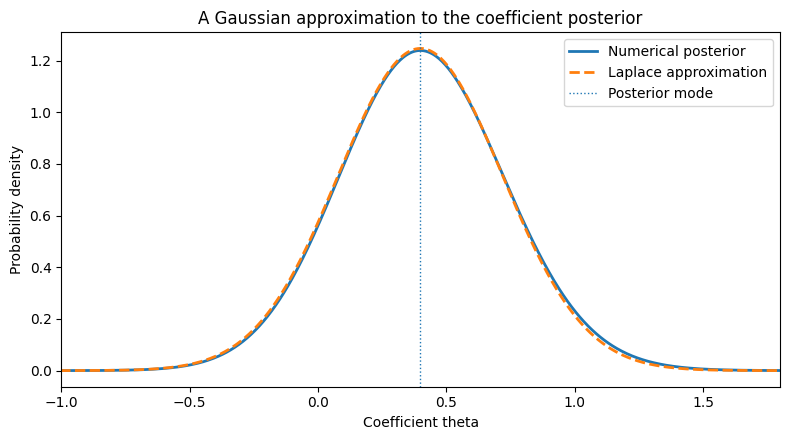

| Quantity | Numerical posterior | Laplace Gaussian |
| --- | --- | --- |
| Mean | 0.40888 | 0.39882 |
| Standard deviation | 0.3241 | 0.31988 |

In [15]:
if ready(1, 2):
    X_example = np.ones((40, 1))
    y_example = np.r_[np.ones(24), np.zeros(16)]
    m_example = np.zeros(1)
    P_example = np.array([[1.0/2.5**2]])
    laplace_example = laplace_approximation(X_example, y_example, m_example, P_example)
    example_mean = float(laplace_example["mean"][0])
    example_sd = float(np.sqrt(laplace_example["covariance"][0, 0]))

    theta_grid = np.linspace(-4.0, 4.0, 2001)
    log_posterior = (24*log_expit(theta_grid) + 16*log_expit(-theta_grid)
                     - theta_grid**2/(2*2.5**2))
    relative_density = np.exp(log_posterior - log_posterior.max())
    posterior_density = relative_density / trapezoid(relative_density, theta_grid)
    laplace_density = norm.pdf(theta_grid, loc=example_mean, scale=example_sd)
    example_reference_mean = trapezoid(theta_grid*posterior_density, theta_grid)
    example_reference_sd = np.sqrt(trapezoid(
        (theta_grid-example_reference_mean)**2*posterior_density, theta_grid))

    fig, ax = plt.subplots(figsize=(8.0, 4.5))
    ax.plot(theta_grid, posterior_density, linewidth=2, label="Numerical posterior")
    ax.plot(theta_grid, laplace_density, linestyle="--", linewidth=2,
            label="Laplace approximation")
    ax.axvline(example_mean, linestyle=":", linewidth=1, label="Posterior mode")
    ax.set(xlabel="Coefficient theta", ylabel="Probability density",
           xlim=(-1.0, 1.8), title="A Gaussian approximation to the coefficient posterior")
    ax.legend()
    fig.tight_layout()
    plt.show()
    table(["Quantity", "Numerical posterior", "Laplace Gaussian"], [
        ["Mean", example_reference_mean, example_mean],
        ["Standard deviation", example_reference_sd, example_sd]])

### 4.3 Return to the intercept-and-slope model

The calculation is unchanged when $\theta$ contains two coefficients.
Use the same function on the original data. The returned mean and covariance
define the Gaussian that will be used for prediction.

In [16]:
if ready(1, 2):
    binary_laplace = laplace_approximation(X, y, m0, P0)
    theta_map = binary_laplace["mean"]
    Sn = binary_laplace["covariance"]
    _, _, H_map = binary_terms(theta_map, X, y, m0, P0)
    np.testing.assert_allclose(H_map @ Sn, np.eye(d), atol=1e-10)
    table(["Coefficient", "Gaussian mean / MAP", "Gaussian standard deviation"], [
        ["Intercept", theta_map[0], np.sqrt(Sn[0, 0])],
        ["Slope", theta_map[1], np.sqrt(Sn[1, 1])]])

| Coefficient | Gaussian mean / MAP | Gaussian standard deviation |
| --- | --- | --- |
| Intercept | -0.38964 | 0.53051 |
| Slope | 0.96143 | 0.37747 |

## 5. Posterior predictive distribution

### 5.1 Integrating over the coefficient posterior

For a new feature vector $x_*$, average the conditional Bernoulli probability over the parameter posterior:
$$
\begin{aligned}
p(y_*\mid x_*,\mathcal D)
&=\int p(y_*\mid x_*,\theta)p(\theta\mid\mathcal D)\,d\theta,\\
p(y_*\mid x_*,\mathcal D)
&\approx r_*^{y_*}(1-r_*)^{1-y_*},\quad y_*\in\{0,1\},\\
r_*&=\mathbb E_q[\sigma(x_*^\top\theta)].
\end{aligned}
$$
Thus the predictive distribution for one future label is Bernoulli. A distribution over its probability
is a different object. The plug-in prediction is $\sigma(x_*^\top\theta_{\rm MAP})$.
It is generally not the expectation above.

Under $q$, the linear projection $a_*=x_*^\top\theta$ is Gaussian. Compute its moments:
$$
\begin{aligned}
m_*&=\mathbb E_q[a_*]=x_*^\top\theta_{\rm MAP},\\
v_*&=\mathbb E_q[(a_*-m_*)^2]
=x_*^\top\mathbb E_q[(\theta-\theta_{\rm MAP})(\theta-\theta_{\rm MAP})^\top]x_*
=x_*^\top S_nx_*.
\end{aligned}
$$
So a $d$-dimensional integral reduces to one dimension:
$$
r_*=\int_{\mathbb R}\sigma(a)\mathcal N(a\mid m_*,v_*)\,da.
$$


Applying the sigmoid to an average logit is not the same as averaging probabilities.
The following example puts equal mass on logits $a=0$ and $a=4$.

In [17]:
toy_logits = np.array([0.0, 4.0])
table(["Calculation", "Class-1 probability"], [
    ["Sigmoid of mean logit", sigmoid(toy_logits.mean())],
    ["Mean of sigmoid probabilities", sigmoid(toy_logits).mean()]])

| Calculation | Class-1 probability |
| --- | --- |
| Sigmoid of mean logit | 0.8808 |
| Mean of sigmoid probabilities | 0.74101 |

For the Gaussian predictive integral, symmetry gives $r_*=1/2$ when $m_*=0$.
When $v_*=0$, the logit is deterministic and $r_*=\sigma(m_*)$.

### 5.2 Gauss–Hermite quadrature

Substitute $a=m_*+\sqrt{v_*}\,t$:
$$
r_*=\frac{1}{\sqrt{2\pi}}\int \sigma(m_*+\sqrt{v_*}\,t)e^{-t^2/2}dt
\approx \frac{1}{\sqrt{2\pi}}\sum_{j=1}^{J_H}\omega_j
\sigma(m_*+\sqrt{v_*}\,t_j).
$$
The `roots_hermitenorm` nodes and weights use $e^{-t^2/2}$ and sum to $\sqrt{2\pi}$.
Do not mix this convention with weights for $e^{-t^2}$.
Increase the order $J_H$ to check numerical convergence. This checks integration under fixed $q$,
not whether $q$ is a good posterior approximation. The analytic logistic–Gaussian shortcut is in Appendix E.

Source for the quadrature convention: SciPy, `roots_hermitenorm` documentation ([4]).

In [55]:
def logistic_normal_mean(mean, variance, order=80):
    """Gauss-Hermite evaluation of E[sigmoid(A)], A ~ N(mean, variance)."""
    mean, variance = np.broadcast_arrays(np.asarray(mean, dtype=float),
                                         np.asarray(variance, dtype=float))
    if np.any(variance < 0):
        raise ValueError("Gaussian variances must be nonnegative.")
    nodes, weights = roots_hermitenorm(order)
    logits = mean[..., None] + np.sqrt(variance)[..., None]*nodes
    return np.sum(sigmoid(logits)*weights, axis=-1)/np.sqrt(2*np.pi)

In [56]:
def test_logistic_normal_mean():
    means = np.array([-2., -0.3, 0., 0.8, 2.5])
    np.testing.assert_allclose(logistic_normal_mean(means, 0.), sigmoid(means), atol=1e-12)
    np.testing.assert_allclose(logistic_normal_mean(0., np.array([0., 0.1, 2., 20.])),
                               0.5, atol=1e-12)
    variances = np.array([0.3, 0.8, 1., 2., 3.])
    out = logistic_normal_mean(means, variances)
    np.testing.assert_allclose(out + logistic_normal_mean(-means, variances), 1., atol=1e-12)
    np.testing.assert_allclose(out, logistic_normal_mean(means, variances, 160), atol=2e-7)
    assert out.shape == means.shape and np.all((out > 0) & (out < 1))
    try:
        logistic_normal_mean(0., -1.)
    except ValueError:
        pass
    else:
        raise AssertionError("A negative variance must raise ValueError.")

test_logistic_normal_mean()

### 5.3 Monte Carlo integration

Draw independent coefficient vectors from the fitted Gaussian:

$$
\theta^{(s)}\sim q(\theta)=\mathcal N(\theta_{\mathrm{MAP}},S_n),
\qquad s=1,\ldots,S.
$$

In NumPy, `rng.multivariate_normal(mean, covariance, size=S)` returns these
coefficient vectors as rows. Reuse each vector at all inputs to obtain one
complete sampled probability curve.

Apply the sigmoid to every sampled logit, then average:

$$
\pi_*^{(s)}=\sigma(x_*^\top\theta^{(s)}),\qquad
\widehat r_*=\frac1S\sum_{s=1}^S\pi_*^{(s)},\qquad
\widehat{\mathrm{SE}}_{\mathrm{MC}}=
\frac{\operatorname{sd}_{\mathrm{sample}}(\pi_*^{(1)},\ldots,\pi_*^{(S)})}{\sqrt S}.
$$

These are independent Gaussian draws, not MCMC. Conditional on fitted $q$,
the mean is unbiased for $r_*$. The standard error measures numerical integration
error, not the spread of the underlying probability distribution.
There is no need to sample Bernoulli labels merely to estimate $r_*$;
the probabilities already give their conditional expectations.

In [57]:
def sample_gaussian(mean, covariance, rng, size):
    """Draw independent coefficient vectors as rows from N(mean, covariance)."""
    if size < 1:
        raise ValueError("size must be positive")
    return rng.multivariate_normal(mean, covariance, size=size, check_valid="raise")

# A small check of the sample shape and approximate moments.
check_mean = np.array([0.3, -0.4])
check_covariance = np.array([[0.4, 0.1], [0.1, 0.7]])
check_draws = sample_gaussian(check_mean, check_covariance, np.random.default_rng(31), 80000)
assert check_draws.shape == (80000, 2)
np.testing.assert_allclose(check_draws.mean(axis=0), check_mean, atol=0.015)
np.testing.assert_allclose(np.cov(check_draws, rowvar=False), check_covariance,
                           atol=0.015, rtol=0.025)

### Exercise 3 — Monte Carlo predictive probabilities

Implement `binary_predictive_mc(X_star, theta_samples)`.
The inputs have shapes $(n_*,d)$ and $(S,d)$. Return
`(mean_probability, mc_standard_error)`, each with shape $(n_*,)$.

Compute `theta_samples @ X_star.T` and apply `sigmoid` to obtain the
$(S,n_*)$ probability matrix. Average over axis 0. For the standard error,
use the sample standard deviation (`ddof=1`) divided by $\sqrt S$.

Run the tests, then compare the Monte Carlo estimates with quadrature
in the examples below.

In [58]:
def binary_predictive_mc(X_star, theta_samples):
    """Average probabilities under S independent coefficient draws; return mean and MC SE."""
    X_star, theta_samples = np.asarray(X_star, float), np.asarray(theta_samples, float)
    if X_star.ndim != 2 or theta_samples.ndim != 2 or X_star.shape[1] != theta_samples.shape[1]:
        raise ValueError("Expected X_star:(n_star,d), theta_samples:(S,d).")
    if len(theta_samples) < 2 or len(X_star) < 1:
        raise ValueError("Need at least two independent draws and one input.")
    if not (np.isfinite(X_star).all() and np.isfinite(theta_samples).all()):
        raise ValueError("Inputs must be finite.")

    a = theta_samples @ X_star.T
    probabilities = sigmoid(a)
    mean_probability = probabilities.mean(axis=0)
    mc_standard_error = probabilities.std(axis=0, ddof=1)/np.sqrt(len(theta_samples))
    return mean_probability, mc_standard_error

In [59]:
def test_binary_predictive_mc():
    # The two-logit puzzle also catches averaging BEFORE the sigmoid.
    Xp, draws = np.ones((1,1)), np.array([[0.], [4.]])
    mean, se = binary_predictive_mc(Xp, draws)
    expected = sigmoid(np.array([0.,4.]))
    np.testing.assert_allclose(mean, [expected.mean()])
    np.testing.assert_allclose(se, [expected.std(ddof=1)/np.sqrt(2)])
    assert not np.isclose(mean[0], sigmoid(2.))
    rng = np.random.default_rng(33)
    Xt, samples = rng.normal(size=(7,3)), rng.normal(size=(30,3))
    values = np.array([sigmoid(Xt @ theta) for theta in samples])
    mean, se = binary_predictive_mc(Xt, samples)
    assert mean.shape == se.shape == (7,)
    np.testing.assert_allclose(mean, values.mean(axis=0))
    np.testing.assert_allclose(se, values.std(axis=0,ddof=1)/np.sqrt(30))
    same = np.repeat(samples[:1], 10, axis=0)
    mean0, se0 = binary_predictive_mc(Xt, same)
    np.testing.assert_allclose(mean0, sigmoid(Xt @ same[0]))
    np.testing.assert_allclose(se0, 0., atol=1e-14)
    try:
        binary_predictive_mc(Xt, samples[:1])
    except ValueError:
        pass
    else:
        raise AssertionError("One draw cannot estimate a sample standard error.")

check_exercise(3, test_binary_predictive_mc)

Exercise 3: checks passed.


True

## 6. Predictive examples

### 6.1 MAP, quadrature, and Monte Carlo

Compare MAP plug-in probabilities with quadrature and Monte Carlo integration under the same Gaussian posterior $q$.
The sampled curves represent variation across coefficient draws. The Monte Carlo standard error measures the numerical error in their estimated average.

Which estimates should approach one another as the number of draws grows?

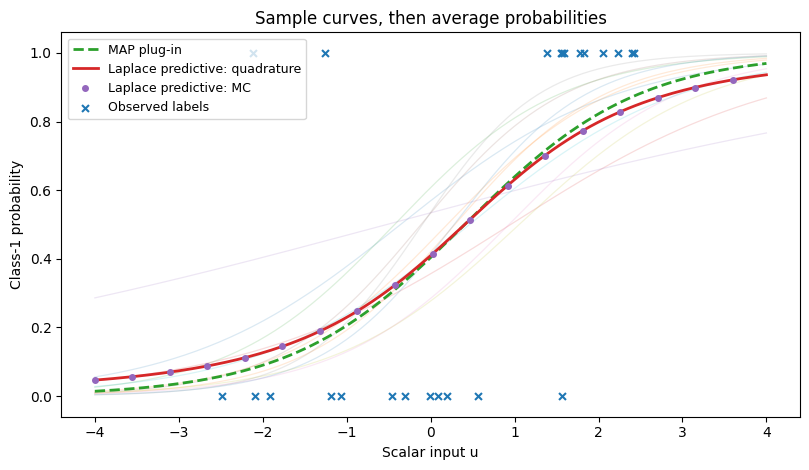

| u | MAP | Quadrature under q | MC under q | MC SE |
| --- | --- | --- | --- | --- |
| -3.5531 | 0.02176 | 0.056665 | 0.056112 | 0.0013717 |
| -0.87151 | 0.22661 | 0.24818 | 0.24897 | 0.0019504 |
| 1.3631 | 0.71523 | 0.70153 | 0.70096 | 0.0018308 |
| 3.5531 | 0.95375 | 0.91963 | 0.91954 | 0.0014587 |

Largest change from 80 to 160 quadrature nodes: 1.2857770403940094e-14


In [60]:
if ready(1, 2, 3):
    u_star = np.linspace(-4.0, 4.0, 180)
    X_star = np.column_stack([np.ones_like(u_star), u_star])
    pred_mean_logit = X_star @ theta_map
    pred_var_logit = np.einsum("ni,ij,nj->n", X_star, Sn, X_star)
    p_map = sigmoid(pred_mean_logit)
    p_gh = logistic_normal_mean(pred_mean_logit, pred_var_logit, order=80)
    p_gh_refined = logistic_normal_mean(pred_mean_logit, pred_var_logit, order=160)
    gh_change = float(np.max(np.abs(p_gh-p_gh_refined)))
    assert gh_change < 3e-5
    draws = sample_gaussian(theta_map, Sn, np.random.default_rng(41), MC_SAMPLES)
    sampled_p = sigmoid(draws @ X_star.T)
    p_mc, mc_se = binary_predictive_mc(X_star, draws)
    lower = sigmoid(pred_mean_logit + norm.ppf(0.05)*np.sqrt(pred_var_logit))
    upper = sigmoid(pred_mean_logit + norm.ppf(0.95)*np.sqrt(pred_var_logit))

    fig, ax = plt.subplots(figsize=(8.2,4.8))
    for j in range(12):
        ax.plot(u_star, sampled_p[j], alpha=0.16, linewidth=0.9)
    ax.plot(u_star, p_map, linestyle="--", linewidth=2, label="MAP plug-in")
    ax.plot(u_star, p_gh, linewidth=2, label="Laplace predictive: quadrature")
    ax.plot(u_star[::10], p_mc[::10], linestyle="none", marker="o", markersize=4, label="Laplace predictive: MC")
    ax.scatter(u,y,marker="x",s=25,label="Observed labels")
    ax.set(xlabel="Scalar input u",ylabel="Class-1 probability",ylim=(-0.06,1.06),
           title="Sample curves, then average probabilities")
    ax.legend(fontsize=9,loc="upper left")
    fig.tight_layout(); plt.show()

    chosen = [10,70,120,169]
    table(["u", "MAP", "Quadrature under q", "MC under q", "MC SE"],
          [[u_star[j],p_map[j],p_gh[j],p_mc[j],mc_se[j]] for j in chosen])
    print("Largest change from 80 to 160 quadrature nodes:", gh_change)

### 6.2 Pointwise probability intervals

Because the sigmoid is increasing, transform Gaussian logit quantiles to obtain a pointwise central 90% interval
for $\pi_*=\sigma(a_*)$ under $q$:
$$
[\sigma(m_*+z_{.05}\sqrt{v_*}),\ \sigma(m_*+z_{.95}\sqrt{v_*})].
$$
It is not a 90% interval for the binary label, and not a simultaneous band over every input.
The future label is $y_*\sim\operatorname{Bernoulli}(r_*)$ under the approximate model.
More MC samples reduce numerical error in an estimated mean, not this interval's underlying width.

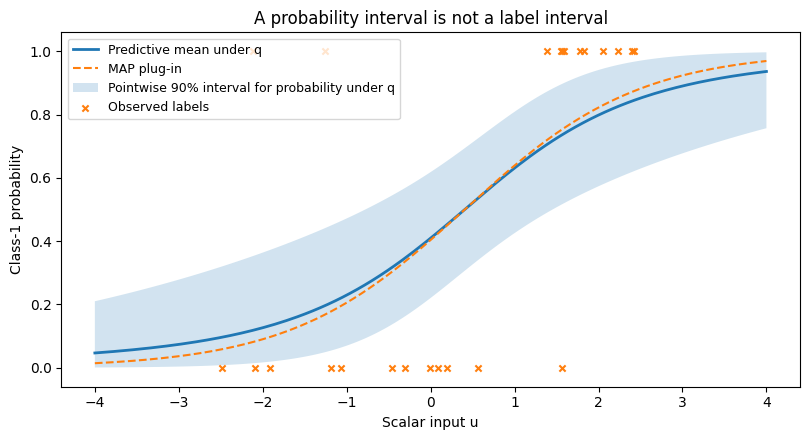

In [24]:
if ready(1, 2, 3):
    fig, ax = plt.subplots(figsize=(8.2,4.5))
    ax.fill_between(u_star,lower,upper,alpha=0.2,label="Pointwise 90% interval for probability under q")
    ax.plot(u_star,p_gh,label="Predictive mean under q",linewidth=2)
    ax.plot(u_star,p_map,linestyle="--",label="MAP plug-in")
    ax.scatter(u,y,marker="x",s=20,label="Observed labels")
    ax.set(xlabel="Scalar input u",ylabel="Class-1 probability",ylim=(-0.06,1.06),
           title="A probability interval is not a label interval")
    ax.legend(fontsize=9,loc="upper left")
    fig.tight_layout(); plt.show()

### 6.3 Monte Carlo convergence

At $u_*=1$, compare $S=16,64,256,1024,4096$ using nested prefixes of one independent draw sequence.
The MC error will not decrease monotonically on every run. Its typical scale is proportional to $S^{-1/2}$;
quadrupling $S$ roughly halves the standard error. The horizontal reference is a 160-node quadrature calculation.

| S | MC mean at u=1 | Estimated MC SE | Absolute error vs quadrature |
| --- | --- | --- | --- |
| 16 | 0.65468 | 0.028364 | 0.02356 |
| 64 | 0.64031 | 0.013059 | 0.0091855 |
| 256 | 0.63642 | 0.0070968 | 0.0052953 |
| 1024 | 0.63325 | 0.0036683 | 0.0021327 |
| 4096 | 0.63077 | 0.0018238 | 0.00035384 |

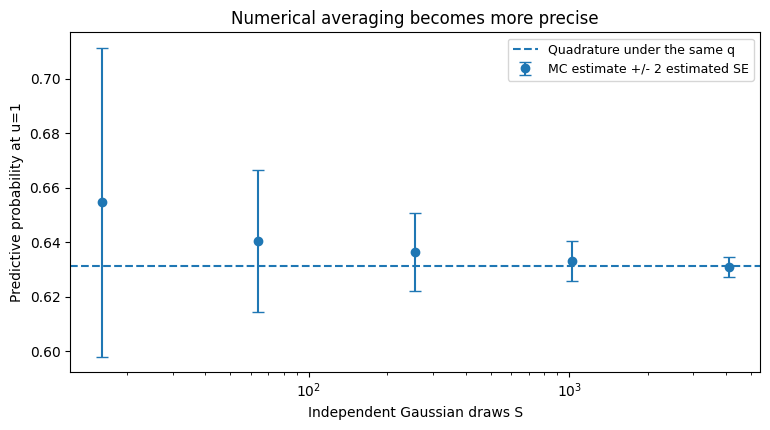

In [25]:
if ready(1, 2, 3):
    x_probe = np.array([[1.,1.]])
    probe_mean = float(x_probe[0] @ theta_map)
    probe_var = float(x_probe[0] @ Sn @ x_probe[0])
    probe_reference = float(logistic_normal_mean(probe_mean,probe_var,160))
    budgets = np.array([16,64,256,1024,4096])
    budget_draws = sample_gaussian(theta_map, Sn, np.random.default_rng(41), int(budgets.max()))
    mc_rows=[]
    for budget in budgets:
        estimate, error = binary_predictive_mc(x_probe,budget_draws[:budget])
        mc_rows.append([int(budget),float(estimate[0]),float(error[0]),abs(float(estimate[0])-probe_reference)])
    table(["S", "MC mean at u=1", "Estimated MC SE", "Absolute error vs quadrature"],mc_rows)
    arr=np.asarray(mc_rows)
    fig,ax=plt.subplots(figsize=(7.8,4.4))
    ax.errorbar(arr[:,0],arr[:,1],yerr=2*arr[:,2],fmt="o",capsize=4,label="MC estimate +/- 2 estimated SE")
    ax.axhline(probe_reference,linestyle="--",label="Quadrature under the same q")
    ax.set(xscale="log",xlabel="Independent Gaussian draws S",ylabel="Predictive probability at u=1",
           title="Numerical averaging becomes more precise")
    ax.legend(fontsize=9); fig.tight_layout(); plt.show()

### 6.4 Uncertainty with a poorly constrained slope

Consider a separate dataset from the same linear model, $p(y=1\mid u)=\sigma(1.5u)$.
Initially, all 24 inputs lie in $[-0.15,0.15]$. In this small interval, probabilities
are close to one-half and positive and negative slopes can both explain the labels.
The prior is $\theta\sim\mathcal N(0,\operatorname{diag}(2.5^2,3^2))$.

The likelihood contribution to slope curvature is $\sum_i p_i(1-p_i)u_i^2$.
Small observed values of $|u_i|$ leave the slope weakly constrained even when the
intercept is better determined. At a new input,

$$
\operatorname{Var}_q(\theta_0+u\theta_1)
=(S_n)_{00}+2u(S_n)_{01}+u^2(S_n)_{11}.
$$

In this example the slope posterior puts substantial mass on both signs, so sampled
probability curves disagree outside the observed interval. No nonlinear features
are needed. We then add 60 observations with inputs spanning $[-3,3]$ and refit
with the same prior. The generating coefficients are used to simulate labels and
draw a reference curve, not passed to either fit.

For each input, let $\pi_*^{(s)}=\sigma(x_*^\top\theta^{(s)})$ and
$\widehat r_*=S^{-1}\sum_s\pi_*^{(s)}$. The same Monte Carlo probabilities estimate
three variance-based quantities:

$$
\begin{aligned}
\widehat U_{\mathrm{total}}(x_*)&=\widehat r_*(1-\widehat r_*),\\
\widehat U_{\mathrm{aleatoric}}(x_*)&=\frac1S\sum_{s=1}^S\pi_*^{(s)}(1-\pi_*^{(s)}),\\
\widehat U_{\mathrm{epistemic}}(x_*)&=\frac1S\sum_{s=1}^S(\pi_*^{(s)}-\widehat r_*)^2,\\
\widehat U_{\mathrm{total}}&=\widehat U_{\mathrm{aleatoric}}+\widehat U_{\mathrm{epistemic}}.
\end{aligned}
$$

Aleatoric uncertainty is the average conditional Bernoulli variance. Epistemic
uncertainty is the variance of the predicted probability across coefficient draws.
Their sum is the total variance of a future binary label under the empirical mixture
of sampled models. These are variances, not entropies.

Use `ddof=0` here so that the finite-sample sum agrees exactly, apart from round-off.
The Monte Carlo standard-error estimate instead uses `ddof=1`. All three quantities
are conditional on the chosen model, prior, and Laplace approximation; they do not
account for every source of model misspecification.

In [26]:
def binary_uncertainty_mc(probability_samples: np.ndarray) -> dict[str, np.ndarray]:
    """Variance-based uncertainties from probability samples with shape (S, n_star)."""
    probability = np.asarray(probability_samples, dtype=float)
    if probability.ndim != 2 or probability.shape[0] < 2 or probability.shape[1] < 1:
        raise ValueError("Expected probability samples with shape (S, n_star), S >= 2.")
    if not np.isfinite(probability).all() or np.any((probability < 0) | (probability > 1)):
        raise ValueError("Probabilities must be finite and lie in [0, 1].")

    mean_probability = probability.mean(axis=0)
    total = mean_probability * (1.0 - mean_probability)
    aleatoric = (probability * (1.0 - probability)).mean(axis=0)
    epistemic = probability.var(axis=0, ddof=0)
    return {"total": total, "aleatoric": aleatoric, "epistemic": epistemic}

In [27]:
def test_binary_uncertainty_mc():
    # Identical probabilities have no between-model variance.
    identical = np.repeat([[0.0, 0.2, 0.7, 1.0]], 8, axis=0)
    result = binary_uncertainty_mc(identical)
    expected = identical[0] * (1.0 - identical[0])
    np.testing.assert_allclose(result["total"], expected, atol=1e-14)
    np.testing.assert_allclose(result["aleatoric"], expected, atol=1e-14)
    np.testing.assert_allclose(result["epistemic"], 0.0, atol=1e-14)

    # A deterministic conditional label has zero conditional variance.
    endpoints = np.array([[0., 1.], [1., 0.], [0., 1.], [1., 0.]])
    result = binary_uncertainty_mc(endpoints)
    np.testing.assert_allclose(result["total"], 0.25)
    np.testing.assert_allclose(result["aleatoric"], 0.0)
    np.testing.assert_allclose(result["epistemic"], 0.25)

    values = np.random.default_rng(54).uniform(size=(37, 11))
    result = binary_uncertainty_mc(values)
    np.testing.assert_allclose(result["total"], result["aleatoric"] + result["epistemic"],
                               rtol=1e-12, atol=1e-14)
    for value in result.values():
        assert value.shape == (11,) and np.all(value >= 0) and np.all(value <= 0.25)

    for invalid in [np.array([0.2, 0.8]), np.ones((1, 2)), np.empty((2, 0)),
                    np.array([[0.2], [np.nan]]), np.array([[0.2], [1.2]])]:
        try:
            binary_uncertainty_mc(invalid)
        except ValueError:
            continue
        raise AssertionError("Invalid probability samples were accepted.")

test_binary_uncertainty_mc()

In [28]:
if ready(1, 2, 3):
    rng_uncertainty = np.random.default_rng(17)
    theta_uncertainty_gen = np.array([0.0, 1.5])
    m_uncertainty = np.zeros(2)
    P_uncertainty = np.diag([1.0 / 2.5**2, 1.0 / 3.0**2])

    u_narrow = np.linspace(-0.15, 0.15, 24)
    X_narrow = np.column_stack([np.ones_like(u_narrow), u_narrow])
    y_narrow = rng_uncertainty.binomial(
        1, sigmoid(X_narrow @ theta_uncertainty_gen)).astype(float)

    u_added = np.linspace(-3.0, 3.0, 60)
    X_added = np.column_stack([np.ones_like(u_added), u_added])
    y_added = rng_uncertainty.binomial(
        1, sigmoid(X_added @ theta_uncertainty_gen)).astype(float)
    X_wider = np.vstack([X_narrow, X_added])
    y_wider = np.concatenate([y_narrow, y_added])

    u_uncertainty = np.linspace(-4.0, 4.0, 201)
    X_uncertainty = np.column_stack([np.ones_like(u_uncertainty), u_uncertainty])
    uncertainty_results = {}
    for name, X_fit, y_fit in [
            ("Narrow inputs", X_narrow, y_narrow),
            ("Wider coverage", X_wider, y_wider)]:
        gaussian = laplace_approximation(X_fit, y_fit, m_uncertainty, P_uncertainty)
        samples = sample_gaussian(gaussian["mean"], gaussian["covariance"],
                                  np.random.default_rng(55), MC_SAMPLES)
        probabilities = sigmoid(samples @ X_uncertainty.T)
        mean_probability, standard_error = binary_predictive_mc(X_uncertainty, samples)
        components = binary_uncertainty_mc(probabilities)
        np.testing.assert_allclose(components["total"],
                                   components["aleatoric"] + components["epistemic"],
                                   rtol=1e-12, atol=1e-14)
        uncertainty_results[name] = {
            "gaussian": gaussian, "samples": samples,
            "probabilities": probabilities, "mean": mean_probability,
            "mc_se": standard_error, **components}

    table(["Training inputs", "MAP slope", "Slope SD under q", "P(slope > 0) under q"], [
        [name, result["gaussian"]["mean"][1],
         np.sqrt(result["gaussian"]["covariance"][1, 1]),
         norm.cdf(result["gaussian"]["mean"][1] /
                  np.sqrt(result["gaussian"]["covariance"][1, 1]))]
        for name, result in uncertainty_results.items()])

| Training inputs | MAP slope | Slope SD under q | P(slope > 0) under q |
| --- | --- | --- | --- |
| Narrow inputs | 1.4683 | 2.5028 | 0.72129 |
| Wider coverage | 1.7699 | 0.43258 | 0.99998 |

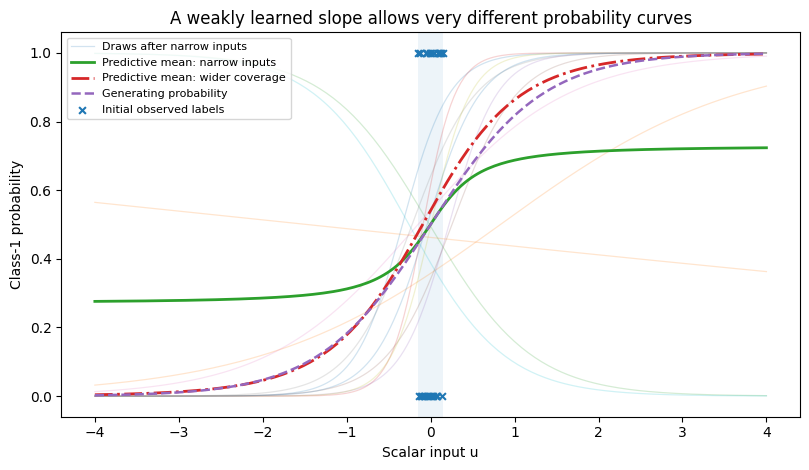

In [29]:
if ready(1, 2, 3):
    narrow = uncertainty_results["Narrow inputs"]
    wider = uncertainty_results["Wider coverage"]
    fig, ax = plt.subplots(figsize=(8.2, 4.8))
    for j in range(12):
        ax.plot(u_uncertainty, narrow["probabilities"][j], alpha=0.2, linewidth=0.9,
                label="Draws after narrow inputs" if j == 0 else None)
    ax.plot(u_uncertainty, narrow["mean"], linewidth=2, label="Predictive mean: narrow inputs")
    ax.plot(u_uncertainty, wider["mean"], linewidth=2, linestyle="-.",
            label="Predictive mean: wider coverage")
    ax.plot(u_uncertainty, sigmoid(X_uncertainty @ theta_uncertainty_gen),
            linestyle="--", linewidth=1.8, label="Generating probability")
    ax.scatter(u_narrow, y_narrow, marker="x", s=24, label="Initial observed labels")
    ax.axvspan(u_narrow.min(), u_narrow.max(), alpha=0.08)
    ax.set(xlabel="Scalar input u", ylabel="Class-1 probability", ylim=(-0.06, 1.06),
           title="A weakly learned slope allows very different probability curves")
    ax.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    plt.show()

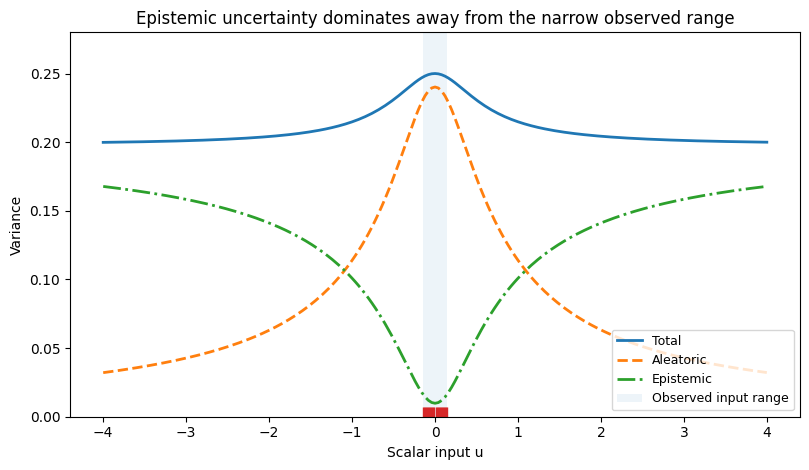

| u | Total | Aleatoric | Epistemic | Epistemic / total |
| --- | --- | --- | --- | --- |
| -4 | 0.19985 | 0.032098 | 0.16775 | 0.83939 |
| -2 | 0.2041 | 0.062981 | 0.14112 | 0.69142 |
| 0 | 0.25 | 0.2402 | 0.0098021 | 0.039209 |
| 2 | 0.20431 | 0.063231 | 0.14108 | 0.69052 |
| 4 | 0.19998 | 0.032177 | 0.1678 | 0.8391 |

In [30]:
if ready(1, 2, 3):
    narrow = uncertainty_results["Narrow inputs"]
    fig, ax = plt.subplots(figsize=(8.2, 4.8))
    for name, style in [("total", "-"), ("aleatoric", "--"), ("epistemic", "-.")]:
        ax.plot(u_uncertainty, narrow[name], linestyle=style, linewidth=2,
                label=name.capitalize())
    ax.axvspan(u_narrow.min(), u_narrow.max(), alpha=0.08, label="Observed input range")
    ax.plot(u_narrow, np.full_like(u_narrow, 0.01), linestyle="none", marker="|", markersize=9,
            transform=ax.get_xaxis_transform())
    ax.set(xlabel="Scalar input u", ylabel="Variance", ylim=(0.0, 0.28),
           title="Epistemic uncertainty dominates away from the narrow observed range")
    ax.legend(fontsize=9, loc="lower right")
    fig.tight_layout()
    plt.show()

    probe_indices = [0, 50, 100, 150, 200]
    table(["u", "Total", "Aleatoric", "Epistemic", "Epistemic / total"], [
        [u_uncertainty[j], narrow["total"][j], narrow["aleatoric"][j],
         narrow["epistemic"][j], narrow["epistemic"][j] / narrow["total"][j]]
        for j in probe_indices])

The next comparison holds the model, prior, and number of Monte Carlo draws fixed.
Only the observations change. Taking more independent Gaussian draws would improve the
integration estimate without learning anything about the slope; adding labels at
new inputs changes the fitted posterior itself.

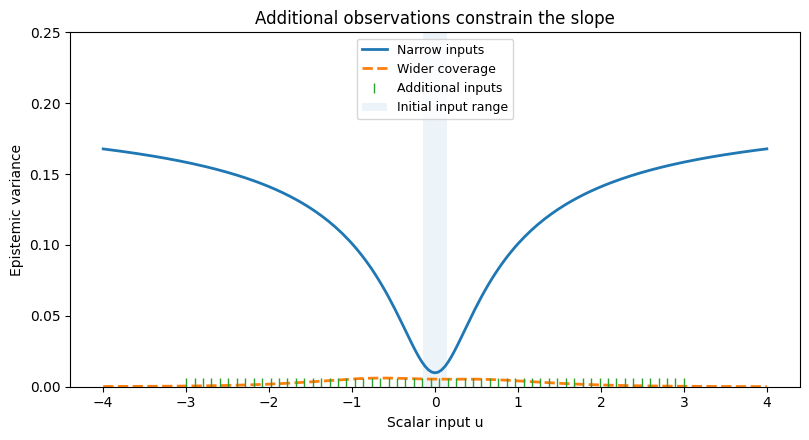

| u | Epistemic: narrow inputs | Epistemic: wider coverage |
| --- | --- | --- |
| -4 | 0.16775 | 0.00014656 |
| -2 | 0.14112 | 0.0018175 |
| 0 | 0.0098021 | 0.0053328 |
| 2 | 0.14108 | 0.0012364 |
| 4 | 0.1678 | 8.8332e-05 |

In [31]:
if ready(1, 2, 3):
    fig, ax = plt.subplots(figsize=(8.2, 4.5))
    for name, style in [("Narrow inputs", "-"), ("Wider coverage", "--")]:
        ax.plot(u_uncertainty, uncertainty_results[name]["epistemic"],
                linestyle=style, linewidth=2, label=name)
    ax.axvspan(u_narrow.min(), u_narrow.max(), alpha=0.08, label="Initial input range")
    ax.plot(u_added, np.full_like(u_added, 0.01), linestyle="none", marker="|", markersize=7,
            transform=ax.get_xaxis_transform(), label="Additional inputs")
    ax.set(xlabel="Scalar input u", ylabel="Epistemic variance", ylim=(0.0, 0.25),
           title="Additional observations constrain the slope")
    ax.legend(fontsize=9, loc="upper center")
    fig.tight_layout()
    plt.show()

    table(["u", "Epistemic: narrow inputs", "Epistemic: wider coverage"], [
        [u_uncertainty[j], uncertainty_results["Narrow inputs"]["epistemic"][j],
         uncertainty_results["Wider coverage"]["epistemic"][j]] for j in probe_indices])

The narrow-input fit leaves appreciable posterior probability on both signs of the
slope. Its coefficient draws agree more closely near the observed inputs and disagree
more strongly during extrapolation. With wider coverage, the fitted slopes concentrate
and the epistemic component becomes smaller in this realization. Conditional label
variation near the class boundary remains.

This is not a universal distance rule: when the slope's sign is already well learned,
linear logistic models can remain confident far from the training inputs. The effect
here comes from a specific weakly identified coefficient and the stated prior.

Why do small training values of $|u|$ constrain the slope less than the intercept?
What changes after observing labels at larger $|u|$, and what changes when only
`MC_SAMPLES` is increased? How would a much tighter slope prior affect the first fit?

# Appendices

In [32]:
RUN_APPENDICES = False  # Set to True to execute the appendix examples.

if RUN_APPENDICES:
    from scipy.linalg import cho_factor, cho_solve, solve_triangular
    from scipy.special import softmax

    def sample_precision(mean, precision, rng, size):
        """Optional linear-algebra implementation using an inverse covariance."""
        if size < 1:
            raise ValueError("size must be positive")
        L = np.linalg.cholesky(precision)
        eps = rng.normal(size=(size, len(mean)))
        return mean + solve_triangular(L.T, eps.T, lower=False).T

    if ready(1, 2):
        A = H_map  # Appendix notation for the inverse Laplace covariance.

## Appendix A. Optimization details and complete separation

### A.1 A numerical Newton step

For $X=\begin{pmatrix}1&-1\\1&0\\1&1\end{pmatrix}$, $y=(0,0,1)^\top$,
$m_0=0$, and $P_0=I_2$, evaluate the objective and its derivatives at $\theta=0$.
The code solves $H\delta=-g$ and compares the objective before and after one step.

Does one Newton step reach the MAP?

In [33]:
if RUN_APPENDICES and ready(1):
    X_step = np.array([[1., -1.], [1., 0.], [1., 1.]])
    y_step = np.array([0., 0., 1.])
    theta_step = np.zeros(2)
    J_step, g_step, H_step = binary_terms(
        theta_step, X_step, y_step, np.zeros(2), np.eye(2))
    delta_step = newton_direction(g_step, H_step)
    J_after = binary_terms(theta_step + delta_step, X_step, y_step,
                           np.zeros(2), np.eye(2))[0]
    np.testing.assert_allclose(delta_step, [-2/7, 2/3])
    table(["Quantity", "Value"], [
        ["Objective at zero", J_step], ["Gradient", g_step],
        ["Hessian diagonal", np.diag(H_step)], ["Newton step", delta_step],
        ["Objective after one step", J_after]])

### A.2 Complete separation and a finite MAP

Suppose there is a vector $v\in\mathbb R^d$ such that
$(2y_i-1)x_i^\top v>0$ for every observation. Along $\theta=t v$, $t\to\infty$,

$$
-\ell_{\mathrm{lik}}(t v)
=\sum_i\log\big(1+e^{-t(2y_i-1)x_i^\top v}\big)\longrightarrow0.
$$

Every term is positive at finite $t$ and decreases along this separating direction.
Thus the likelihood approaches its supremum of one without reaching it at finite
coefficients; no finite unregularized MLE exists. The positive-definite Gaussian
prior adds a quadratic penalty tending to infinity, so the MAP remains finite.

This argument requires every direction, including any intercept direction, to be
controlled by the prior for the simple coercivity proof used here. An unpenalized
intercept or a singular prior needs a separate existence argument. The examples penalize the intercepts explicitly.

### A.3 Prior sensitivity

An intercept-free model with $x=(-2,-1,1,2)$ and $y=(0,0,1,1)$ isolates complete separation.
The unregularized loss approaches zero without reaching it at a finite coefficient.
Each proper Gaussian prior gives a finite MAP. Changing the prior requires refitting; the likelihood curvature then changes as well.

How do the fitted slope and its uncertainty change with the prior standard deviation?

In [34]:
if RUN_APPENDICES:
    if ready(1):
        X_sep = np.array([-2., -1., 1., 2.])[:, None]
        y_sep = np.array([0., 0., 1., 1.])
        separation_rows = []
        for tau in [0.5, 1., 2.5, 5.]:
            fit_sep = fit_newton(lambda b: binary_terms(
                b, X_sep, y_sep, np.zeros(1), np.eye(1)/tau**2), np.zeros(1))
            separation_rows.append([tau, fit_sep["mode"][0], 1/np.sqrt(fit_sep["hessian"][0, 0])])
        table(["Prior SD", "Finite MAP slope", "Laplace slope SD"], separation_rows)
        t = np.array([0., 1., 2., 4., 8., 16.])
        logits_sep = t[:, None] * X_sep[:, 0]
        losses = -(y_sep[None, :] * log_expit(logits_sep)
                   + (1-y_sep[None, :]) * log_expit(-logits_sep)).sum(axis=1)
        assert np.all(np.diff(losses) < 0) and np.all(losses > 0)
        table(["Unregularized slope", "Negative log likelihood"], list(zip(t, losses)))

## Appendix B. Evidence and a numerical posterior audit

### B.1 General local derivation

Let $z\in\mathbb R^d$ have a density $p(z)=f(z)/Z$, where $f$ is positive near an
interior mode $z_0$, $Z=\int f(z)\,dz$ is finite and positive, and
$h(z)=\log f(z)$ is three times continuously differentiable near $z_0$.
Assume explicitly that $\nabla h(z_0)=0$ and
$A=-\nabla^2h(z_0)\succ0$: the mode must be nondegenerate.
With $\Delta=z-z_0$, Taylor's formula gives

$$
h(z)=h(z_0)-\tfrac12\Delta^\top A\Delta+R_3(\Delta).
$$

If the operator norm of the third derivative is at most $M$ on the line segment
from $z_0$ to $z$, Taylor's integral remainder yields
$|R_3(\Delta)|\leq M\|\Delta\|^3/6$.
Discarding this remainder and exponentiating gives a Gaussian-shaped kernel:

$$
f(z)\approx f(z_0)\exp\{-\tfrac12\Delta^\top A\Delta\}.
$$

To normalize it, factor $A=LL^\top$ and make the change of variables
$t=L^\top\Delta$. The Jacobian is
$dz=|\det L|^{-1}dt=|A|^{-1/2}dt$. Thus

$$
\int_{\mathbb R^d}e^{-\Delta^\top A\Delta/2}\,dz
=|A|^{-1/2}\prod_{j=1}^d\int_{\mathbb R}e^{-t_j^2/2}\,dt_j
=(2\pi)^{d/2}|A|^{-1/2}.
$$

Dividing the kernel by this integral identifies

$$
q(z)=\mathcal N(z\mid z_0,A^{-1}),\qquad
Z_{\mathrm L}=f(z_0)(2\pi)^{d/2}|A|^{-1/2}.
$$

The subscript $\mathrm L$ denotes the Laplace estimate, so
$\log Z_{\mathrm L}=\log f(z_0)+\tfrac d2\log(2\pi)-\tfrac12\log|A|$.
For a Cholesky factor, $\log|A|=2\sum_j\log L_{jj}$.

This is a local approximation. A small Taylor remainder near the mode is not alone
a bound on the integrated error; the rest of the mass must also be controlled.
In a regular fixed-dimensional large-sample setting, curvature often grows as $n$
and typical displacements shrink as $n^{-1/2}$. A third derivative of order $n$
then gives a local cubic term of order $n^{-1/2}$. This scaling argument explains
why concentration can help; it is not an accuracy theorem for every posterior.

A strict local maximum alone does not imply a
positive-definite negative Hessian. For example, $h(z)=-z^4$ has a strict mode at
zero but $-h''(0)=0$. The nondegeneracy assumption above is an additional condition,
not a consequence of strictness. For our Gaussian-prior logistic model it follows
from $H(\theta)\succeq P_0\succ0$.

Dividing the entire objective by $n$ leaves its minimizer unchanged. Averaging only
the likelihood but leaving the penalty unchanged instead multiplies the effective
prior precision by $n$. If the Hessian of $J/n$ is used, the posterior precision
is $n\nabla^2(J/n)$, not just $\nabla^2(J/n)$.

### B.2 Evidence retains the prior normalizer

Set $f(\theta)=p(y\mid X,\theta)p(\theta)=\exp\{-J(\theta)+c_0\}$.
Here $c_0=\tfrac12\log|P_0|-\tfrac d2\log(2\pi)$ is the Gaussian prior normalizer in log space. Its mode is $\theta_{\mathrm{MAP}}$, and its negative log curvature is

$$
A=H(\theta_{\mathrm{MAP}})=X^\top W_{\mathrm{MAP}}X+P_0,
\qquad S_n=A^{-1}.
$$

The subscript $n$ in $S_n$ indicates that all $n$ observations have been used.
Then $q(\theta)=\mathcal N(\theta_{\mathrm{MAP}},S_n)$ and

$$
\log Z_{\mathrm L}=-J(\theta_{\mathrm{MAP}})+c_0
+\tfrac d2\log(2\pi)-\tfrac12\log|A|.
$$

Dropping $c_0$ is harmless for the mode and curvature but incorrect for evidence.
A Laplace evidence estimate is not a lower bound on $\log Z$.

If $Av_j=\lambda_jv_j$ for a unit eigenvector $v_j$, the variance along that direction
under $q$ is $v_j^\top S_n v_j=1/\lambda_j$. This is why sharp local curvature means
small local uncertainty. The mean of $q$ equals the posterior mode; it need not
equal the exact posterior mean. Likewise $S_n$ is not guaranteed to equal the exact
posterior covariance.

In [35]:
if RUN_APPENDICES and ready(1, 2):
    def laplace_summary(mode, precision, log_joint_at_mode):
        """Compute covariance and log evidence of the local Gaussian kernel."""
        L = np.linalg.cholesky(precision)
        dim = len(mode)
        covariance = cho_solve((L, True), np.eye(dim))
        logdet = 2.0*np.log(np.diag(L)).sum()
        log_evidence = log_joint_at_mode + 0.5*dim*np.log(2*np.pi) - 0.5*logdet
        return {"mean": np.asarray(mode).copy(), "covariance": covariance,
                "log_evidence": float(log_evidence), "cholesky_precision": L}

    def test_laplace_summary():
        precision = np.array([[4., 1.2], [1.2, 2.]])
        mean = np.array([0.3, -0.4])
        # f is itself a normalized Gaussian; its exact normalizer is one.
        log_peak = 0.5*np.linalg.slogdet(precision)[1] - np.log(2*np.pi)
        result = laplace_summary(mean, precision, log_peak)
        np.testing.assert_allclose(precision @ result["covariance"], np.eye(2), atol=1e-12)
        np.testing.assert_allclose(result["log_evidence"], 0., atol=1e-12)
        L = result["cholesky_precision"]
        np.testing.assert_allclose(L@L.T, precision, atol=1e-12)

    test_laplace_summary()

    if ready(1, 2):
        c0 = 0.5*np.linalg.slogdet(P0)[1] - 0.5*d*np.log(2*np.pi)
        log_joint_map = -binary_fit["value"] + c0
        binary_laplace = laplace_summary(theta_map, A, log_joint_map)
        Sn = binary_laplace["covariance"]
        table(["Quantity", "Laplace value"], [
            ["Mean / posterior mode", theta_map],
            ["Coefficient standard deviations", np.sqrt(np.diag(Sn))],
            ["Coefficient correlation", Sn[0, 1]/np.sqrt(Sn[0, 0]*Sn[1, 1])],
            ["Log evidence", binary_laplace["log_evidence"]]])

### B.3 A numerical posterior reference

Since $d=2$, use product trapezoidal quadrature on a rectangular coefficient grid.
Let $\theta_j$ denote a grid node and $\omega_j>0$ its integration weight
(the product of two one-dimensional trapezoidal weights). Then

$$
Z_{\mathrm{grid}}=\sum_j\omega_j f(\theta_j),\qquad
\rho_j=\frac{\omega_j f(\theta_j)}{Z_{\mathrm{grid}}},\qquad
\sum_j\rho_j=1.
$$

The approximate posterior mean is $\mu_{\mathrm{grid}}=\sum_j\rho_j\theta_j$;
the covariance is
$S_{\mathrm{grid}}=\sum_j\rho_j(\theta_j-\mu_{\mathrm{grid}})
(\theta_j-\mu_{\mathrm{grid}})^\top$.
For numerical stability, normalize the values
$\log\omega_j+\log f(\theta_j)$ using `logsumexp`.

There are two numerical errors: truncating $\mathbb R^2$ to a finite rectangle and
discretizing that rectangle. First enlarge the box, then refine the grid. Agreement
is an empirical convergence check, not a rigorous bound on the omitted tails.
The reported boundary-strip mass is only a diagnostic inside the box.

In [36]:
if RUN_APPENDICES and ready(1, 2):
    def binary_log_joint_batch(points, X, y, m0, P0):
        """Normalized prior times binary likelihood, evaluated in bounded-size chunks."""
        dim = X.shape[1]
        prior_constant = 0.5*np.linalg.slogdet(P0)[1] - 0.5*dim*np.log(2*np.pi)
        values = []
        for start in range(0, len(points), 5000):
            block = points[start:start + 5000]
            logits = block @ X.T
            delta = block - m0
            loss = -(y[None, :] * log_expit(logits)
                     + (1-y[None, :]) * log_expit(-logits)).sum(axis=1)
            penalty = 0.5*np.einsum("bi,ij,bj->b", delta, P0, delta)
            values.append(-loss - penalty + prior_constant)
        return np.concatenate(values)

    def posterior_grid(mode, covariance, X, y, m0, P0, radius, points_per_axis):
        if X.shape[1] != 2 or len(mode) != 2 or points_per_axis < 5:
            raise ValueError("This reference requires two coefficients and at least five grid nodes per axis.")
        sd = np.sqrt(np.diag(covariance))
        axes = [np.linspace(mode[j] - radius*sd[j], mode[j] + radius*sd[j],
                            points_per_axis) for j in range(2)]
        t0, t1 = np.meshgrid(*axes, indexing="xy")
        nodes = np.column_stack([t0.ravel(), t1.ravel()])
        weights_1d = []
        for axis in axes:
            weights = np.ones(len(axis))*(axis[1] - axis[0])
            weights[[0, -1]] *= 0.5
            weights_1d.append(weights)
        weights = np.outer(weights_1d[1], weights_1d[0]).ravel()
        log_joint = binary_log_joint_batch(nodes, X, y, m0, P0)
        log_z = float(logsumexp(log_joint + np.log(weights)))
        mass = np.exp(log_joint + np.log(weights) - log_z)
        mean = mass @ nodes
        delta = nodes - mean
        covariance_ref = (delta.T*mass) @ delta
        mass_grid = mass.reshape(t0.shape)
        rim = np.ones(t0.shape, dtype=bool)
        rim[3:-3, 3:-3] = False
        return {"nodes": nodes, "mass": mass, "mean": mean, "covariance": covariance_ref,
                "log_evidence": log_z, "t0": t0, "t1": t1,
                "log_density": (log_joint - log_z).reshape(t0.shape),
                "boundary_strip_mass": float(mass_grid[rim].sum())}

    if ready(1, 2):
        grid_rows = []
        previous_log_z = None
        previous_grid = None
        moment_changes = []
        for radius, resolution in [(8., 321), (10., 401), (10., 601)]:
            grid = posterior_grid(theta_map, Sn, X, y, m0, P0, radius, resolution)
            change = "—" if previous_log_z is None else abs(grid["log_evidence"] - previous_log_z)
            grid_rows.append([radius, resolution, grid["log_evidence"], change,
                              grid["mean"][0], grid["mean"][1], grid["boundary_strip_mass"]])
            if previous_grid is not None:
                mean_change = np.max(np.abs(grid["mean"] - previous_grid["mean"]))
                covariance_change = np.max(np.abs(grid["covariance"] - previous_grid["covariance"]))
                moment_changes.append([radius, resolution, mean_change, covariance_change])
            previous_log_z = grid["log_evidence"]
            previous_grid = grid
        table(["Box half-width (local sd)", "Nodes / axis", "log Z", "Change in log Z",
               "Mean intercept", "Mean slope", "Boundary strip mass"], grid_rows, digits=7)
        assert abs(grid["mass"].sum() - 1) < 1e-12
        assert grid_rows[-2][3] < 1e-5, "Enlarge the reference box further."
        assert grid_rows[-1][3] < 1e-5, "Refine the reference grid further."
        table(["Quantity", "Quadrature reference", "Laplace"], [
            ["Mean intercept", grid["mean"][0], theta_map[0]],
            ["Mean slope", grid["mean"][1], theta_map[1]],
            ["SD intercept", np.sqrt(grid["covariance"][0, 0]), np.sqrt(Sn[0, 0])],
            ["SD slope", np.sqrt(grid["covariance"][1, 1]), np.sqrt(Sn[1, 1])],
            ["log Z", grid["log_evidence"], binary_laplace["log_evidence"]]])
        table(["Box half-width", "Nodes / axis", "Largest mean change", "Largest covariance-entry change"], moment_changes, digits=7)
        assert moment_changes[-1][2] < 1e-5 and moment_changes[-1][3] < 1e-5

The next contour plot compares equal density heights, not equal credible masses.
The solid contours use the numerical normalizer; the dashed contours use the
normalized Laplace density. Separate markers distinguish the converged MAP
estimate from the numerical posterior mean.

In [37]:
if RUN_APPENDICES and ready(1, 2):
    from matplotlib.lines import Line2D
    if ready(1, 2):
        delta = grid["nodes"] - theta_map
        log_q = (0.5*np.linalg.slogdet(A)[1] - np.log(2*np.pi)
                 - 0.5*np.einsum("bi,ij,bj->b", delta, A, delta))
        q_image = np.exp(log_q).reshape(grid["t0"].shape)
        density = np.exp(grid["log_density"])
        levels = np.max(density)*np.array([0.10, 0.35, 0.70])
        fig, ax = plt.subplots(figsize=(7.1, 5.5))
        ax.contour(grid["t0"], grid["t1"], density, levels=levels, linestyles="solid")
        ax.contour(grid["t0"], grid["t1"], q_image, levels=levels, linestyles="dashed")
        mode_marker, = ax.plot(*theta_map, marker="x", markersize=9, linestyle="none", label="MAP")
        mean_marker, = ax.plot(*grid["mean"], marker="o", markersize=6, linestyle="none", label="Reference mean")
        sd = np.sqrt(np.diag(Sn))
        ax.set(xlim=(theta_map[0]-3.7*sd[0], theta_map[0]+3.7*sd[0]),
               ylim=(theta_map[1]-3.7*sd[1], theta_map[1]+4.2*sd[1]),
               xlabel="Intercept θ₀", ylabel="Slope θ₁", title="Posterior shape: numerical reference and Laplace")
        ax.legend(handles=[Line2D([], [], linestyle="-", label="Reference density"),
                           Line2D([], [], linestyle="--", label="Laplace density"),
                           mode_marker, mean_marker], loc="upper left")
        fig.tight_layout()
        plt.show()

### B.4 Separate approximation error from integration error

The grid integrates $p(\theta\mid\mathcal D)$ numerically. The Gauss–Hermite and Monte Carlo predictions in Section 6 integrate $q$.
A discrepancy between converged grid and Gaussian predictions is not fixed by drawing more samples from $q$.

In [38]:
if RUN_APPENDICES and ready(1, 2, 3):
    p_grid = np.zeros(len(X_star))
    for start in range(0,len(grid["nodes"]),4000):
        block = grid["nodes"][start:start+4000]
        mass = grid["mass"][start:start+4000]
        p_grid += mass @ sigmoid(block @ X_star.T)
    fig,ax=plt.subplots(figsize=(8,4.5))
    ax.plot(u_star,p_grid,linestyle=":",linewidth=2,label="Numerical posterior reference")
    ax.plot(u_star,p_gh,label="Laplace predictive (quadrature)")
    ax.plot(u_star,p_map,linestyle="--",label="MAP plug-in")
    ax.set(xlabel="Scalar input u",ylabel="Class-1 probability",title="Different coefficient distributions, different predictions")
    ax.legend();fig.tight_layout();plt.show()
    table(["u", "Grid predictive", "Laplace quadrature"],[[u_star[j],p_grid[j],p_gh[j]] for j in [10,70,120,169]])

## Appendix C. Correlations and a Bayesian softmax last layer

In [39]:
if RUN_APPENDICES:
    from matplotlib.lines import Line2D
    from sklearn.datasets import load_digits
    from sklearn.decomposition import PCA
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import roc_auc_score, roc_curve

### C.1 Two different ways to discard correlations

Let $A\succ0$ be the full posterior precision and $S=A^{-1}$ its covariance.
The diagonal-Hessian approximation retains only the diagonal of $A$. Define

$$
D_A=\operatorname{diag}(A_{11},\ldots,A_{dd}),\qquad
q_{\mathrm{diagH}}=\mathcal N(\theta_{\mathrm{MAP}},D_A^{-1}).
$$

This differs from discarding the off-diagonal entries of the full covariance,
which would give
$\mathcal N(\theta_{\mathrm{MAP}},\operatorname{diag}(S_{11},\ldots,S_{dd}))$.
In general $1/A_{jj}\neq(A^{-1})_{jj}$.

To see the difference, partition a precision matrix around coordinate $j$:

$$
A=\begin{pmatrix} a & b^\top\\ b & C\end{pmatrix}.
$$

Solving $A(s,t)^\top=(1,0)^\top$ gives $t=-C^{-1}bs$ and
$(a-b^\top C^{-1}b)s=1$. Hence

$$
S_{jj}=\frac{1}{a-b^\top C^{-1}b}\ \geq\ \frac1a.
$$

Here $C$ is the precision submatrix for the other coordinates, $b$ is the vector of
cross-precision entries, and the positive denominator is the Schur complement.
The value $1/a$ is the conditional variance of coordinate $j$ given the others in
this Gaussian. It is not its marginal variance. Equality requires $b=0$.

This coordinatewise inequality does not order predictive variances for every
input. Correlations enter $x^\top Sx$ with signs determined by the components of $x$.
Nor is taking a diagonal Hessian invariant under a rotation of parameter coordinates.

### Worked example — diagonal approximations

The two functions below implement $D_A^{-1}$ and
$\operatorname{diag}((A^{-1})_{11},\ldots,(A^{-1})_{dd})$.
The plot compares their directional variances with those of the full covariance.
Only the inverse-diagonal-Hessian construction is used in the classification
comparison.

Do smaller coordinate variances guarantee a smaller predictive variance in every direction?

In [40]:
if RUN_APPENDICES:
    def diagonal_hessian_covariance(A):
        """Covariance after retaining only the diagonal of the precision."""
        diagonal = np.diag(A)
        if np.any(diagonal <= 0):
            raise ValueError("Precision diagonal must be positive.")
        return np.diag(1.0/diagonal)

    def diagonal_marginal_covariance(A):
        """Keep the marginal variances of the full Gaussian but remove correlations."""
        full = cho_solve(cho_factor(A, lower=True), np.eye(len(A)))
        return np.diag(np.diag(full))

In [41]:
if RUN_APPENDICES:
    def test_diagonal_covariances():
        At = np.array([[4., 1.5], [1.5, 1.]])
        Sd = diagonal_hessian_covariance(At)
        Sm = diagonal_marginal_covariance(At)
        np.testing.assert_allclose(Sd, np.diag([0.25, 1.]))
        np.testing.assert_allclose(Sm, np.diag([1./1.75, 4./1.75]))
        assert np.all(np.diag(Sm) >= np.diag(Sd))
        np.testing.assert_allclose(diagonal_hessian_covariance(np.diag([2., 3.])),
                                   diagonal_marginal_covariance(np.diag([2., 3.])))

    test_diagonal_covariances()

    At = np.array([[4., 1.5], [1.5, 1.]])
    full_cov = cho_solve(cho_factor(At, lower=True), np.eye(2))
    covariances = {"Full covariance": full_cov,
                  "Inverse diagonal Hessian": diagonal_hessian_covariance(At),
                  "Diagonal of full covariance": diagonal_marginal_covariance(At)}
    angles = np.linspace(0, 2*np.pi, 361)
    directions = np.column_stack([np.cos(angles), np.sin(angles)])
    fig, ax = plt.subplots()
    for (name, covariance), style in zip(covariances.items(), ["-", "--", ":"]):
        variance = np.einsum("ni,ij,nj->n", directions, covariance, directions)
        ax.plot(angles/np.pi, variance, linestyle=style, label=name)
    ax.set(xlabel="Direction angle / π", ylabel="Variance in the unit direction",
           title="Marginal variances alone do not determine predictive uncertainty")
    ax.legend()
    fig.tight_layout()
    plt.show()
    table(["Gaussian", "Variance of coordinate 1", "Variance of coordinate 2"],
          [[name, cov[0, 0], cov[1, 1]] for name, cov in covariances.items()])

### C.2 A Bayesian softmax last layer

#### C.2.1 Classification on frozen features

Fit a three-class softmax classifier on images of digits 0, 1, and 2. Each image
has 8 × 8 pixels. Use 12 principal-component scores as features, scaled using the
training data, and include an intercept. The feature map is then frozen; only the
last-layer coefficients are treated as random.

Compare MAP predictions with posterior-predictive probabilities under full-Hessian
and diagonal-Hessian Laplace approximations. Evaluate classification on held-out
images of the three known classes and confidence on digits 3–9, whose labels are
absent from the classifier's output space. This comparison is adapted from [2],
Problems 1–2; background on Bayesian last-layer inference is given in [3].

The feature map and hyperparameters are fixed before test-set and
out-of-distribution evaluation. Only training inputs fit PCA or its scaling;
only training labels fit the classifier. Report the validation set separately.
No hyperparameter is selected using out-of-distribution examples.

### C.3 Frozen features and data splits

Let $r\in\mathbb R^{64}$ be an image flattened to a vector after dividing pixel
values by 16. PCA is fitted on the training inputs. If $\bar r$ is their mean and
$v_j\in\mathbb R^{64}$ is the $j$th retained unit principal direction, define

$$
t_j(r)=v_j^\top(r-\bar r),\qquad
s_j^2=\frac1{n_{\mathrm{tr}}}\sum_{i\in\mathrm{train}}t_j(r_i)^2,
\qquad
\phi(r)=\big(1,t_1(r)/s_1,\ldots,t_{12}(r)/s_{12}\big)^\top.
$$

Here $n_{\mathrm{tr}}$ is the training-set size, and all $s_j$ are nonzero in this
dataset. Training PCA scores have zero empirical mean, so this second moment is
their empirical variance. The feature dimension, including the intercept, is
$d_\phi=13$. Once fitted, $\phi$ is deterministic and frozen. Scaling affects the
meaning of an isotropic coefficient prior, so the scaling is part of the model
specification, not a harmless operation after fitting.

Use a stratified 60% / 20% / 20% split of digits 0, 1, 2, and reserve every image of
digits 3–9 for the out-of-distribution evaluation. The raw digit values 0, 1, 2 are
also the zero-based class indices used in code. In the mathematics below the three
class indices are written $k=1,2,3$; this is just an indexing convention.

In [42]:
if RUN_APPENDICES:
    digits = load_digits()
    raw_images = np.asarray(digits.data, dtype=float)/16.0
    raw_labels = digits.target.astype(int)
    id_indices = np.flatnonzero(raw_labels < 3)
    ood_indices = np.flatnonzero(raw_labels >= 3)
    train_indices, remainder = train_test_split(
        id_indices, test_size=0.4, stratify=raw_labels[id_indices], random_state=17)
    validation_indices, test_indices = train_test_split(
        remainder, test_size=0.5, stratify=raw_labels[remainder], random_state=18)
    assert not set(train_indices) & set(validation_indices)
    assert not set(train_indices) & set(test_indices)
    assert not set(validation_indices) & set(test_indices)
    assert not set(id_indices) & set(ood_indices)

    pca = PCA(n_components=12, svd_solver="full")
    pca.fit(raw_images[train_indices])
    train_scores = pca.transform(raw_images[train_indices])
    score_scale = train_scores.std(axis=0, ddof=0)
    assert np.all(score_scale > 0)

    def frozen_features(images):
        """Apply the training-fitted feature map; never refit on new inputs."""
        scores = pca.transform(np.asarray(images, dtype=float))/score_scale
        return np.column_stack([np.ones(len(scores)), scores])

    Phi_train = frozen_features(raw_images[train_indices])
    Phi_validation = frozen_features(raw_images[validation_indices])
    Phi_test = frozen_features(raw_images[test_indices])
    Phi_ood = frozen_features(raw_images[ood_indices])
    y_train = raw_labels[train_indices]
    y_validation = raw_labels[validation_indices]
    y_test = raw_labels[test_indices]
    K = 3
    d_phi = Phi_train.shape[1]
    alpha = 1.0  # Fixed in advance; all coefficients, including intercepts, are penalized.

    table(["Split", "Images", "Original digit labels", "Used to fit"], [
        ["Training", len(train_indices), "0, 1, 2", "PCA, feature scales, MAP weights"],
        ["Validation", len(validation_indices), "0, 1, 2", "Nothing in this fixed protocol"],
        ["Test", len(test_indices), "0, 1, 2", "Nothing"],
        ["Out of distribution", len(ood_indices), "3–9", "Nothing"]])
    print("Feature dimension = {}; random coefficients = {}; prior precision = {}".format(
        d_phi, K*d_phi, alpha))

    # A single-axis image strip; these examples are the first two training images per class.
    example_indices = [idx for label in range(3)
                       for idx in train_indices[raw_labels[train_indices] == label][:2]]
    strip = np.hstack([raw_images[idx].reshape(8, 8) for idx in example_indices])
    fig, ax = plt.subplots(figsize=(9.0, 2.2))
    ax.imshow(strip, interpolation="nearest")
    ax.set_xticks([8*j + 3.5 for j in range(len(example_indices))])
    ax.set_xticklabels(["Digit {}".format(raw_labels[idx]) for idx in example_indices])
    ax.set_yticks([])
    ax.set_title("Training examples: the three in-distribution classes")
    fig.tight_layout()
    plt.show()

### C.4 From binary coefficients to a multiclass weight matrix

Let $W_{\mathrm{cls}}\in\mathbb R^{K\times d_\phi}$ contain row vectors
$w_k^\top$, one for each class. It is distinct from the binary diagonal curvature matrix $W$ in Section 1.
Let $\Phi\in\mathbb R^{n_{\mathrm{tr}}\times d_\phi}$ have rows $\phi(r_i)^\top$.
For observation $i$, define logits $a_{ik}=w_k^\top\phi(r_i)$ and probabilities

$$
p_{ik}=\frac{e^{a_{ik}}}{\sum_{\ell=1}^{K}e^{a_{i\ell}}}.
$$

Let $Y_{ik}=1$ if observation $i$ belongs to class $k$, and zero otherwise;
$Y\in\mathbb R^{n_{\mathrm{tr}}\times K}$ is the one-hot label matrix.
The likelihood is $\prod_i\prod_k p_{ik}^{Y_{ik}}$.

Define $\beta=\operatorname{vec}_{\mathrm{row}}(W_{\mathrm{cls}})
=(w_1^\top,\ldots,w_K^\top)^\top\in\mathbb R^{m}$, where $m=Kd_\phi$.
This row-stacking convention is NumPy's `W.reshape(-1, order="C")`.
The fixed Gaussian prior is $\beta\sim\mathcal N(0,\alpha^{-1}I_m)$.
Its precision is $P_0=\alpha I_m$; $A$ denotes the posterior precision.

Taking minus the log likelihood and adding the prior penalty gives

$$
J_K(\beta)=\sum_i\left[\log\sum_k e^{a_{ik}}-\sum_kY_{ik}a_{ik}\right]
+\frac\alpha2\|\beta\|^2.
$$

To compute `logsumexp` stably, subtract $c_i=\max_k a_{ik}$ inside the exponentials
and add it outside the logarithm:
$\log\sum_k e^{a_{ik}}=c_i+\log\sum_k e^{a_{ik}-c_i}$.
The subtracted quantity cancels algebraically; it does not change the model.

#### C.4.1 Gradient and block Hessian

Differentiating a normalized exponential gives

$$
\frac{\partial p_{ik}}{\partial a_{i\ell}}
=p_{ik}\big(\delta_{k\ell}-p_{i\ell}\big),
$$

where $\delta_{k\ell}$ is the Kronecker delta (one for equal indices, zero otherwise).
Define $p_i=(p_{i1},\ldots,p_{iK})^\top$ and
$R_i=\operatorname{diag}(p_i)-p_ip_i^\top\in\mathbb R^{K\times K}$.
The derivative of the loss with respect to $a_{ik}$ is $p_{ik}-Y_{ik}$, hence

$$
\nabla_{W_{\mathrm{cls}}}J_K=(P-Y)^\top\Phi+\alpha W_{\mathrm{cls}},
\qquad P=(p_{ik}).
$$

Differentiating row $k$ with respect to row $\ell$ yields the $d_\phi\times d_\phi$
Hessian block

$$
[\nabla_\beta^2J_K]_{k\ell}
=\sum_i p_{ik}(\delta_{k\ell}-p_{i\ell})\phi(r_i)\phi(r_i)^\top
+\alpha\delta_{k\ell}I_{d_\phi}.
$$

Equivalently, with $\otimes$ denoting the Kronecker product (a block matrix whose
$(k,\ell)$ block is the corresponding scalar times the second matrix),

$$
H_K(\beta)=\sum_i R_i\otimes\big[\phi(r_i)\phi(r_i)^\top\big]+\alpha I_m.
$$

For a perturbation $U\in\mathbb R^{K\times d_\phi}$, set
$b_i=U\phi(r_i)\in\mathbb R^K$. Its likelihood quadratic form is
$\sum_i b_i^\top R_i b_i$. Each summand equals
$\sum_k p_{ik}b_{ik}^2-(\sum_kp_{ik}b_{ik})^2$, a nonnegative categorical variance.
Adding $\alpha\|U\|_F^2$ makes the Hessian positive definite for $\alpha>0$.
Here $\|U\|_F^2=\sum_{k,j}U_{kj}^2$. The prior also makes $J_K$ coercive, so the
same existence and uniqueness argument as in Section 2 applies.

What are the dimensions of one Hessian block? Why is $\operatorname{diag}(p_i)-p_i p_i^\top$ positive semidefinite?

### Worked example — the softmax last-layer Hessian

The implementation below returns $J_K$, its row-stacked gradient, and its Hessian.
The contraction with `np.einsum` assembles the blocks in the order
(class, feature, class, feature), consistent with the coefficient vector.

At zero weights, $p_{ik}=1/K$ and
$R_i=I_K/K-\mathbf1_K\mathbf1_K^\top/K^2$. Thus the Hessian is
$R_i\otimes(\Phi^\top\Phi)+\alpha I_m$ at this point. This provides an analytic
check before comparing derivatives with finite differences.

In [43]:
if RUN_APPENDICES:
    def softmax_terms(beta, Phi, labels, K, alpha):
        """Summed softmax loss plus isotropic Gaussian penalty; class-major ordering."""
        feature_dim = Phi.shape[1]
        W_cls = np.asarray(beta).reshape(K, feature_dim)
        logits = Phi @ W_cls.T
        probabilities = softmax(logits, axis=1)
        targets = np.eye(K)[labels]
        value = np.sum(logsumexp(logits, axis=1) - logits[np.arange(len(labels)), labels])
        value += 0.5*alpha*(beta @ beta)
        gradient = ((probabilities - targets).T @ Phi).reshape(-1) + alpha*beta
        R = (np.einsum("ik,kl->ikl", probabilities, np.eye(K))
             - np.einsum("ik,il->ikl", probabilities, probabilities))
        # Axes before reshape: (class k, feature a, class l, feature b).
        hessian = np.einsum("ikl,ia,ib->kalb", R, Phi, Phi, optimize=True)
        hessian = hessian.reshape(K*feature_dim, K*feature_dim)
        hessian += alpha*np.eye(len(beta))
        return float(value), gradient, hessian

In [44]:
if RUN_APPENDICES:
    def test_softmax_terms():
        rng = np.random.default_rng(61)
        Pt = rng.normal(size=(8, 3))
        yt = np.array([0, 1, 2, 1, 0, 2, 2, 1])
        Kt, at = 3, 0.7
        zero = np.zeros(Kt*Pt.shape[1])
        f, g, H = softmax_terms(zero, Pt, yt, Kt, at)
        R0 = np.eye(Kt)/Kt - np.ones((Kt, Kt))/Kt**2
        np.testing.assert_allclose(f, len(yt)*np.log(Kt))
        np.testing.assert_allclose(g, ((np.ones((len(yt), Kt))/Kt - np.eye(Kt)[yt]).T@Pt).reshape(-1))
        np.testing.assert_allclose(H, np.kron(R0, Pt.T@Pt) + at*np.eye(len(zero)))
        point = rng.normal(scale=0.3, size=len(zero))
        f, g, H = softmax_terms(point, Pt, yt, Kt, at)
        gn = fd_gradient(lambda b: softmax_terms(b, Pt, yt, Kt, at)[0], point)
        Hn = fd_jacobian(lambda b: softmax_terms(b, Pt, yt, Kt, at)[1], point)
        np.testing.assert_allclose(g, gn, atol=3e-7, rtol=3e-7)
        np.testing.assert_allclose(H, Hn, atol=3e-7, rtol=3e-7)
        np.testing.assert_allclose(H, H.T, atol=1e-12)
        assert np.linalg.eigvalsh(H).min() >= at - 1e-10
        fb, gb, Hb = softmax_terms(point*10000, Pt, yt, Kt, at)
        assert np.isfinite(fb) and np.isfinite(gb).all() and np.isfinite(Hb).all()

    test_softmax_terms()

    multi_fit = fit_newton(lambda b: softmax_terms(b, Phi_train, y_train, K, alpha),
                           np.zeros(K*d_phi), tol=1e-8)
    beta_map = multi_fit["mode"]
    A_multi = multi_fit["hessian"]
    W_map = beta_map.reshape(K, d_phi)
    p_validation_map = softmax(Phi_validation @ W_map.T, axis=1)
    validation_accuracy = np.mean(p_validation_map.argmax(axis=1) == y_validation)
    table(["MAP fit diagnostic", "Value"], [
        ["Validation accuracy", validation_accuracy],
        ["Validation mean negative log likelihood",
         -np.log(p_validation_map[np.arange(len(y_validation)), y_validation]).mean()],
        ["Newton updates", len(multi_fit["history"])-1],
        ["Final gradient infinity norm", multi_fit["history"][-1, 2]],
        ["Smallest posterior precision eigenvalue", np.linalg.eigvalsh(A_multi).min()]])

### C.5 Shared logit shifts and posterior correlations

Adding the same feature coefficient vector $c\in\mathbb R^{d_\phi}$ to every
class row changes every logit by $c^\top\phi(r)$ and leaves softmax probabilities
unchanged. Thus the likelihood alone does not identify this shared-shift direction.
The proper prior does not remove the likelihood symmetry, but it makes the posterior
precision nonsingular and its mode unique.

More precisely, use the unit shared-class vector $\mathbf1_K/\sqrt K$ and its
orthogonal complement as a basis for class space. For an isotropic zero-mean prior,
this orthogonal change of coordinates factorizes the prior into a shared component
and contrast components. The likelihood depends only on the contrasts, so the
posterior of the shared component remains its prior. In matrix terms, for any $c$,

$$
H_{\mathrm{lik}}\operatorname{vec}_{\mathrm{row}}(\mathbf1_K c^\top)=0,
\quad
A_{\mathrm{multi}}\operatorname{vec}_{\mathrm{row}}(\mathbf1_K c^\top)
=\alpha\operatorname{vec}_{\mathrm{row}}(\mathbf1_K c^\top).
$$

At the mode the class rows therefore sum to zero. The following check verifies the
shared-shift curvature explicitly. Diagonalizing the Hessian destroys some of these
correlations, so its predictive changes cannot be described simply as “less
coefficient variance means more confident predictions.”

Can uncertainty in a shared logit shift change the predictive probabilities?

In [45]:
if RUN_APPENDICES:
    rng = np.random.default_rng(62)
    c = rng.normal(size=d_phi)
    shared_shift = np.tile(c, K)
    np.testing.assert_allclose(A_multi @ shared_shift, alpha*shared_shift, atol=2e-10)
    np.testing.assert_allclose(W_map.sum(axis=0), 0., atol=2e-8)
    np.testing.assert_allclose(softmax(Phi_test @ W_map.T, axis=1),
                               softmax(Phi_test @ (W_map + c).T, axis=1), atol=1e-12)
    print("Common-logit shift and prior-curvature checks passed.")
    # Normalize the Hessian entrywise to reveal structure without scale domination.
    sd_A = np.sqrt(np.diag(A_multi))
    normalized_A = A_multi/sd_A[:, None]/sd_A[None, :]
    fig, ax = plt.subplots(figsize=(6.6, 5.3))
    image = ax.imshow(normalized_A, interpolation="nearest", vmin=-1, vmax=1)
    fig.colorbar(image, ax=ax, label="A[j,k] / sqrt(A[j,j] A[k,k])")
    ax.set_xticks([d_phi*j + (d_phi-1)/2 for j in range(K)])
    ax.set_yticks([d_phi*j + (d_phi-1)/2 for j in range(K)])
    ax.set_xticklabels(["Class {}".format(j) for j in range(K)])
    ax.set_yticklabels(["Class {}".format(j) for j in range(K)])
    ax.set(xlabel="Coefficient block", ylabel="Coefficient block",
           title="Full last-layer curvature contains cross-class structure")
    fig.tight_layout()
    plt.show()

### C.6 Compare MAP, full Laplace, and diagonal-Hessian Laplace

#### C.6.1 The two approximate posteriors

With the same fitted mode $\widehat\beta=\beta_{\mathrm{MAP}}$, define

$$
q_{\mathrm{full}}(\beta)=\mathcal N(\widehat\beta,A_{\mathrm{multi}}^{-1}),
\qquad
q_{\mathrm{diagH}}(\beta)=\mathcal N\big(\widehat\beta,
[\operatorname{diag}(A_{\mathrm{multi}})]^{-1}\big).
$$

Here $\operatorname{diag}(A_{\mathrm{multi}})$ means the diagonal matrix retaining
its diagonal entries, not a vector. Both approximations use the summed-data
posterior Hessian, including the prior. Their mode and feature extractor are
identical. Only their covariance structures differ.

For a new image $r_*$, let $a_*=W_{\mathrm{cls}}\phi(r_*)\in\mathbb R^K$ be its
logit vector. Under either Gaussian coefficient approximation its logit covariance
has entries

$$
\operatorname{Cov}(a_{*k},a_{*\ell})
=\phi(r_*)^\top S_{k\ell}\phi(r_*),
$$

where $S_{k\ell}$ is the corresponding covariance block between coefficient rows.
This follows by expanding the covariance of the two linear functions.
The logits are correlated in general; treating them as independent is another
approximation, not full last-layer Laplace.

The predictive probability for class $k$ is

$$
r_{*k}=\mathbb E_q\left[\frac{e^{a_{*k}}}{\sum_{\ell=1}^K e^{a_{*\ell}}}\right]
\approx\widehat r_{*k}=\frac1S\sum_{s=1}^S
\operatorname{softmax}_k\big(W_{\mathrm{cls}}^{(s)}\phi(r_*)\big).
$$

Average the probabilities after softmax, not the logits before softmax.
The mean of the sampled logits approaches the MAP logits and would discard the
intended model averaging.

### Exercise 4 — Softmax predictive probabilities

Implement `softmax_predictive_mc(Phi, beta_samples, K, batch_size=128)`.
Complete the batching loop by computing the softmax probabilities,
their sample mean, and the Monte Carlo standard error. Return a pair
`(mean_probability, mc_standard_error)`, each shaped
`(number_of_inputs, K)`. Reuse each coefficient sample over all input batches.
Compute the standard error with the sample standard deviation (`ddof=1`); require
at least two independent samples. The MAP predictions are evaluated separately.

The coefficient draws are independent normals. There is no Markov-chain mixing
error here, but posterior-approximation error remains.

In [46]:
if RUN_APPENDICES:
    def softmax_predictive_mc(Phi, beta_samples, K, batch_size=128):
        """Average softmax probabilities under independent Gaussian coefficient draws."""
        if beta_samples.ndim != 2 or beta_samples.shape[1] != K*Phi.shape[1]:
            raise ValueError("Sample shape must be (S, K * feature_dimension).")
        if len(beta_samples) < 2 or batch_size < 1:
            raise ValueError("Need at least two samples and a positive batch_size.")
        W_samples = beta_samples.reshape(len(beta_samples), K, Phi.shape[1])
        probabilities, standard_errors = [], []
        for start in range(0, len(Phi), batch_size):
            block = Phi[start:start + batch_size]
            logits = np.einsum("nd,skd->snk", block, W_samples, optimize=True)

            values = softmax(logits, axis=-1)
            probabilities.append(values.mean(axis=0))
            standard_errors.append(values.std(axis=0, ddof=1)/np.sqrt(len(beta_samples)))

        return np.concatenate(probabilities), np.concatenate(standard_errors)

In [47]:
if RUN_APPENDICES:
    def test_predictive_averaging():
        rng = np.random.default_rng(71)
        features = rng.normal(size=(11, 3))
        samples = rng.normal(size=(20, 9))
        expected_values = np.array([softmax(features @ b.reshape(3, 3).T, axis=1)
                                    for b in samples])
        mean, se = softmax_predictive_mc(features, samples, K=3, batch_size=4)
        np.testing.assert_allclose(mean, expected_values.mean(axis=0), atol=1e-13)
        np.testing.assert_allclose(se, expected_values.std(axis=0, ddof=1)/np.sqrt(20), atol=1e-13)
        np.testing.assert_allclose(mean.sum(axis=1), 1., atol=1e-13)
        mean2, se2 = softmax_predictive_mc(features, samples, K=3, batch_size=30)
        np.testing.assert_allclose(mean, mean2, atol=1e-13)
        np.testing.assert_allclose(se, se2, atol=1e-13)
        # Identical coefficients give plug-in probabilities and zero numerical variation.
        same = np.repeat(samples[:1], 10, axis=0)
        mean0, se0 = softmax_predictive_mc(features, same, K=3)
        np.testing.assert_allclose(mean0, expected_values[0], atol=1e-13)
        np.testing.assert_allclose(se0, 0., atol=1e-13)

    check_exercise(4, test_predictive_averaging)

    if ready(4):
        samples_full = sample_precision(beta_map, A_multi, np.random.default_rng(90), MC_SAMPLES)
        covariance_diag = diagonal_hessian_covariance(A_multi)
        samples_diag = (beta_map + np.random.default_rng(91).normal(size=(MC_SAMPLES, len(beta_map)))
                        *np.sqrt(np.diag(covariance_diag)))
        predictions = {}
        prediction_se = {}
        for split, features in [("Validation", Phi_validation), ("Test", Phi_test), ("OOD", Phi_ood)]:
            predictions[split] = {"MAP": softmax(features @ W_map.T, axis=1)}
            prediction_se[split] = {"MAP": np.zeros((len(features), K))}
            for name, samples in [("Full Laplace", samples_full), ("Diagonal Hessian", samples_diag)]:
                pred, se = softmax_predictive_mc(features, samples, K)
                predictions[split][name] = pred
                prediction_se[split][name] = se
                np.testing.assert_allclose(pred.sum(axis=1), 1., atol=1e-12)
        print("Predictive integration completed with {} independent draws per approximation.".format(MC_SAMPLES))

## Appendix D. Calibration, scoring rules, and OOD detection

### D.1 Evaluation quantities

For $n_{\mathrm{ev}}$ labeled evaluation images, let $r_{ik}$ be a method's
predicted probability for class $k$, and let $Y_{ik}$ be the one-hot target.
The predicted class is $\widehat y_i=\arg\max_k r_{ik}$.
We report accuracy, mean negative log likelihood, and the multiclass Brier score:

$$
\operatorname{accuracy}=\frac1{n_{\mathrm{ev}}}\sum_i
\mathbf1\{\widehat y_i=y_i\},\qquad
\operatorname{NLL}=-\frac1{n_{\mathrm{ev}}}\sum_i\log r_{i,y_i},\qquad
\operatorname{Brier}=\frac1{n_{\mathrm{ev}}}\sum_i\sum_k(r_{ik}-Y_{ik})^2.
$$

Here $\mathbf1\{\cdot\}$ is an indicator. The Brier definition is the sum over
classes, not an additional average over $K$. These are distinct diagnostics: lower
confidence does not by itself imply better NLL, Brier score, or calibration.

For each image also define maximum class probability
$c_i=\max_k r_{ik}$. For OOD detection use the score $s_i=1-c_i$, with OOD as the
positive class. The ROC curve compares threshold-dependent true-positive and
false-positive rates; its area (AUROC) measures the ranking of OOD above
in-distribution test images. It is a discrimination metric, not a calibration test.
We do not assign 3-class accuracy or NLL to digits 3–9: their true labels are absent
from the classifier's label space.

The coefficient draws and seed are fixed before these evaluations. Validation, test,
and OOD numbers must not be combined into a single “accuracy” measure.

In [48]:
if RUN_APPENDICES:
    def classification_metrics(probability, labels):
        if np.any(probability < 0) or not np.allclose(probability.sum(axis=1), 1.):
            raise ValueError("Rows must be probability vectors.")
        labels = np.asarray(labels, dtype=int)
        targets = np.eye(probability.shape[1])[labels]
        accuracy = np.mean(probability.argmax(axis=1) == labels)
        # This floor protects the diagnostic logarithm, not the inference computation.
        observed = np.maximum(probability[np.arange(len(labels)), labels], np.finfo(float).tiny)
        nll = -np.log(observed).mean()
        brier = np.mean(np.sum((probability - targets)**2, axis=1))
        return float(accuracy), float(nll), float(brier)

    if ready(4):
        evaluation_rows = []
        for split, labels in [("Validation", y_validation), ("Test", y_test)]:
            for method, pred in predictions[split].items():
                acc, nll, brier = classification_metrics(pred, labels)
                evaluation_rows.append([split, method, acc, nll, brier, pred.max(axis=1).mean(),
                                        prediction_se[split][method].max()])
        table(["Split", "Method", "Accuracy", "NLL", "Brier", "Mean max probability", "Largest MC SE"],
              evaluation_rows)
        ood_labels = np.r_[np.zeros(len(y_test)), np.ones(len(Phi_ood))]
        ood_rows = []
        for method in predictions["Test"]:
            confidence_id = predictions["Test"][method].max(axis=1)
            confidence_ood = predictions["OOD"][method].max(axis=1)
            scores = 1.0 - np.r_[confidence_id, confidence_ood]
            ood_rows.append([method, confidence_ood.mean(), np.mean(confidence_ood > 0.9),
                             roc_auc_score(ood_labels, scores), prediction_se["OOD"][method].max()])
        table(["Method", "Mean OOD max probability", "OOD fraction above 0.9", "OOD AUROC", "Largest OOD MC SE"],
              ood_rows)

### D.2 Calibration diagnostics

Calibration asks whether predicted probabilities agree with empirical outcome frequencies, not whether the
model is merely less confident. NLL and Brier measure more than calibration alone ([5]).

For top-label calibration of this multiclass model, define confidence $c_i=\max_k r_{ik}$ and correctness
$b_i=\mathbf 1\{\arg\max_k r_{ik}=y_i\}$. In confidence bin $B_j$, compare
$\bar c_j=|B_j|^{-1}\sum_{i\in B_j}c_i$ with $\bar b_j=|B_j|^{-1}\sum_{i\in B_j}b_i$.
Our explicitly defined binned diagnostic is
$$
\widehat{\mathrm{ECE}}=\sum_{j:|B_j|>0}\frac{|B_j|}{n}|\bar b_j-\bar c_j|.
$$
The diagram plots $(\bar c_j,\bar b_j)$ for nonempty bins. Bin counts are reported.
This is a top-label, not an all-class calibration test. Results depend on binning and on this small test set;
a zero or small empirical ECE is not proof of population calibration.

No calibrator is fitted here. A fitted calibrator would require held-out calibration data rather than using the
test set for fitting. We do not evaluate class-probability calibration on unseen labels 3–9.

In [49]:
if RUN_APPENDICES:
    def top_label_reliability(probability, labels, n_bins=10):
        """Equal-width confidence bins; return counts, mean confidence/accuracy and binned ECE."""
        probability, labels = np.asarray(probability,float), np.asarray(labels,int)
        if probability.ndim != 2 or labels.shape != (len(probability),) or not len(labels):
            raise ValueError("Expected nonempty probability:(n,K), labels:(n,).")
        if not isinstance(n_bins,(int,np.integer)) or n_bins < 1:
            raise ValueError("n_bins must be a positive integer.")
        if not np.isfinite(probability).all() or np.any(probability<0) or not np.allclose(probability.sum(1),1.):
            raise ValueError("Rows must be finite probability vectors.")
        confidence = probability.max(axis=1)
        correctness = (probability.argmax(axis=1)==labels).astype(float)
        bin_id = np.minimum((confidence*n_bins).astype(int),n_bins-1)
        count=np.bincount(bin_id,minlength=n_bins)
        mean_c=np.full(n_bins,np.nan); mean_b=np.full(n_bins,np.nan)
        for j in np.flatnonzero(count):
            keep=bin_id==j
            mean_c[j]=confidence[keep].mean();mean_b[j]=correctness[keep].mean()
        keep=count>0
        ece=float(np.sum(count[keep]/len(labels)*np.abs(mean_b[keep]-mean_c[keep])))
        return count,mean_c,mean_b,ece

    # Perfect deterministic predictions: both occupied-bin coordinates are (1,1).
    tc,tm,ta,te=top_label_reliability(np.eye(3),np.arange(3),10)
    assert tc.sum()==3 and te==0
    np.testing.assert_allclose(tm[tc>0],1.)
    np.testing.assert_allclose(ta[tc>0],1.)

    if ready(4):
        fig,ax=plt.subplots(figsize=(6.7,5.0))
        calibration_rows=[]
        for (name,pred),style in zip(predictions["Test"].items(),["-","--",":"]):
            count,confidence,accuracy,ece=top_label_reliability(pred,y_test,10)
            keep=count>0
            ax.plot(confidence[keep],accuracy[keep],marker="o",linestyle=style,label=name)
            for j in np.flatnonzero(keep):
                calibration_rows.append([name,int(j),int(count[j]),confidence[j],accuracy[j]])
        ax.plot([0,1],[0,1],linestyle="-.",label="Perfect top-label calibration")
        ax.set(xlabel="Mean confidence in bin",ylabel="Fraction correct in bin",xlim=(0,1),ylim=(0,1.03),
               title="Held-out top-label reliability: binning is a diagnostic")
        ax.legend(fontsize=9);fig.tight_layout();plt.show()
        table(["Method","Bin index","Count","Mean confidence","Fraction correct"],calibration_rows)
        table(["Method","ECE (5 bins)","ECE (10 bins)","ECE (15 bins)"],
              [[name]+[top_label_reliability(pred,y_test,b)[3] for b in [5,10,15]]
               for name,pred in predictions["Test"].items()])

### D.3 Confidence distributions and OOD images

The histograms below use the same bins and show proportions, not raw counts;
the test and OOD sample sizes differ. A low maximum probability can indicate
ambiguity among known classes, an unfamiliar input, or a deliberately diffuse
model. It is not itself a probability that the image is out of distribution.

The example images are the first held-out images of digits 3, 6, and 9 in the
stored dataset order, chosen without consulting model confidence. Every prediction
is forced to be one of 0, 1, 2 because the model has no “other” class.

In [50]:
if RUN_APPENDICES:
    if ready(4):
        bins = np.linspace(1.0/K, 1.0, 22)
        styles = ["-", "--", ":"]
        for split, title in [("Test", "Maximum class probability on held-out known classes"),
                              ("OOD", "Maximum class probability on unseen digit classes")]:
            fig, ax = plt.subplots()
            for (method, pred), style in zip(predictions[split].items(), styles):
                confidence = pred.max(axis=1)
                ax.hist(confidence, bins=bins, weights=np.ones(len(confidence))/len(confidence),
                        histtype="step", linewidth=1.9, linestyle=style, label=method)
            ax.set(xlabel="Maximum class probability", ylabel="Fraction of images per bin",
                   title=title, xlim=(1.0/K, 1.0))
            ax.legend()
            fig.tight_layout()
            plt.show()

        chosen_ood_positions = [np.flatnonzero(raw_labels[ood_indices] == label)[0]
                                for label in [3, 6, 9]]
        chosen_raw_indices = ood_indices[chosen_ood_positions]
        image_strip = np.hstack([raw_images[idx].reshape(8, 8) for idx in chosen_raw_indices])
        fig, ax = plt.subplots(figsize=(9.0, 4.0))
        ax.imshow(image_strip, interpolation="nearest")
        captions = []
        for pos, idx in zip(chosen_ood_positions, chosen_raw_indices):
            lines = ["True digit {} (unseen)".format(raw_labels[idx])]
            for method, pred in predictions["OOD"].items():
                prob = pred[pos]
                short_name = {"MAP": "MAP", "Full Laplace": "Full", "Diagonal Hessian": "Diag-H"}[method]
                lines.append("{}: digit {}, p={:.2f}".format(short_name, prob.argmax(), prob.max()))
            captions.append("\n".join(lines))
        ax.set_xticks([3.5, 11.5, 19.5])
        ax.set_xticklabels(captions, fontsize=10)
        ax.set_yticks([])
        ax.set_title("An unseen class is not an available output label")
        fig.tight_layout()
        plt.show()

The ROC curve uses $1-\max_k r_k$ only as a ranking score. Its diagonal line is the
chance-ranking reference. Improvements on this one choice of unknown classes
need not transfer to other distribution shifts. Last-layer inference also ignores
uncertainty in the feature extractor itself.

In [51]:
if RUN_APPENDICES:
    if ready(4):
        fig, ax = plt.subplots(figsize=(6.4, 5.0))
        for (method, pred_id), style in zip(predictions["Test"].items(), ["-", "--", ":"]):
            scores = 1.0 - np.r_[pred_id.max(axis=1), predictions["OOD"][method].max(axis=1)]
            fpr, tpr, thresholds = roc_curve(ood_labels, scores)
            auc = roc_auc_score(ood_labels, scores)
            ax.plot(fpr, tpr, linestyle=style, label="{} (AUROC {:.3f})".format(method, auc))
        ax.plot([0, 1], [0, 1], linestyle="-.", label="Chance ranking")
        ax.set(xlabel="False-positive rate: known-class test images flagged OOD",
               ylabel="True-positive rate: unseen digit images flagged OOD",
               title="OOD discrimination, not a calibration guarantee", xlim=(0, 1), ylim=(0, 1.01))
        ax.legend(fontsize=9, loc="lower right")
        fig.tight_layout()
        plt.show()

### D.4 Comparing evaluation criteria

Does the method with the lowest mean OOD confidence also have the lowest held-out NLL?
Which differences are sensitive to the number of Monte Carlo draws?

Lower OOD confidence does not imply a better test log score. Increasing the number of independent coefficient draws reduces integration error, but does not remove limitations due to the posterior approximation, frozen features, model specification, or finite evaluation sample.

In [52]:
if RUN_APPENDICES:
    if ready(4):
        nll_by_method = {name: classification_metrics(pred, y_test)[1]
                         for name, pred in predictions["Test"].items()}
        conf_by_method = {name: pred.max(axis=1).mean() for name, pred in predictions["OOD"].items()}
        table(["Method", "Test NLL", "Mean OOD confidence"],
              [[name, nll_by_method[name], conf_by_method[name]] for name in nll_by_method])
        print("Lowest test NLL in this run:", min(nll_by_method, key=nll_by_method.get))
        print("Lowest mean OOD confidence in this run:", min(conf_by_method, key=conf_by_method.get))

## Appendix E. Analytic shortcut and a tail warning

### E.1 A logistic–Gaussian approximation

An analytic approximation to the logistic-normal integral can be obtained by
replacing the logistic function with a scaled probit function. Let $\Phi_{\mathrm N}$ and $\varphi_{\mathrm N}$ denote
the standard normal CDF and density, respectively, and set $\kappa=\sqrt{\pi/8}$.
Matching derivatives at zero motivates
$\sigma(a)\approx\Phi_{\mathrm N}(\kappa a)$: both functions equal $1/2$ at zero,
and

$$
\sigma'(0)=\tfrac14,\qquad
\left.\frac d{da}\Phi_{\mathrm N}(\kappa a)\right|_{a=0}
=\kappa\varphi_{\mathrm N}(0)=\frac\kappa{\sqrt{2\pi}}=\tfrac14.
$$

For $a\sim\mathcal N(m,v)$, introduce an independent $u\sim\mathcal N(0,1)$.
Then

$$
\mathbb E[\Phi_{\mathrm N}(\kappa a)]
=\Pr(u\leq\kappa a)
=\Phi_{\mathrm N}\!\left(\frac{\kappa m}{\sqrt{1+\kappa^2v}}\right),
$$

because $\kappa a-u$ is normal with mean $\kappa m$ and variance $1+\kappa^2v$.
Applying the logistic–probit approximation a second time gives

$$
\mathbb E[\sigma(a)]\ \approx\
\sigma\!\left(\frac{m}{\sqrt{1+\pi v/8}}\right).
$$

The intermediate probit integral is exact; the two substitutions involving the
logistic function are approximate. The formula approximates the logistic-normal integral. For the stated expression, increasing $v$ shrinks the
magnitude of the effective logit. It is not a claim about all possible non-Gaussian
posteriors or all distribution shifts.

### E.2 Distance from training data does not force probability one-half

For $a(u)=\theta_0+u\theta_1$ and Gaussian $q$ with positive slope variance,
$\sigma(\theta_0+u\theta_1)\to\mathbf1\{\theta_1>0\}$ almost surely as $u\to+\infty$.
Bounded convergence yields
$$
\lim_{u\to+\infty}\mathbb E_q\sigma(\theta_0+u\theta_1)
=\Pr_q(\theta_1>0)
=\Phi\!\left(\frac{(\theta_{\rm MAP})_1}{\sqrt{(S_n)_{11}}}\right),
$$
which is generally not $1/2$. The logit mean and variance both change along this input ray.
Do not confuse this with sending $v\to\infty$ while holding $m$ fixed.

## Appendix F. Gaussian maximum entropy

### F.1 Maximum entropy under moment constraints

This is independent of Laplace's derivation. For a density $p$ on $\mathbb R$ with
finite mean $\mu$, variance $\sigma^2>0$ and well-defined differential entropy,
compare it with $\varphi=\mathcal N(\mu,\sigma^2)$. Then

$$
D_{\mathrm{KL}}(p\Vert\varphi)
=-h(p)-\mathbb E_p\log\varphi(X)
=\frac12\log(2\pi e\sigma^2)-h(p)\geq0.
$$

The second equality uses only $\mathbb E_p[(X-\mu)^2]=\sigma^2$.
Equality holds exactly for the Gaussian density almost everywhere. Translation
invariance means that fixing the variance alone permits any Gaussian mean.
In $d$ dimensions, the bound is $h(p)\leq\frac12\log[(2\pi e)^d\det S]$ for
positive-definite covariance $S$.

A Gaussian maximizes entropy given moments in the chosen coordinates; it is not
an automatically non-informative prior. Laplace instead derives a Gaussian from a
local second-order Taylor expansion. It does not know the exact posterior moments.

In [53]:
if RUN_APPENDICES:
    entropy_rows = [
        ["Gaussian", "N(0,1)", 0.5*np.log(2*np.pi*np.e)],
        ["Logistic", "scale sqrt(3)/pi", 2+np.log(np.sqrt(3)/np.pi)],
        ["Laplace", "scale 1/sqrt(2)", 1+np.log(np.sqrt(2))],
        ["Uniform", "[-sqrt(3), sqrt(3)]", np.log(2*np.sqrt(3))],
    ]
    assert all(row[2] <= entropy_rows[0][2] + 1e-12 for row in entropy_rows)
    table(["Unit-variance distribution", "Parameters", "Differential entropy (nats)"], entropy_rows)

## Appendix G. Pretrained features and repeated Monte Carlo integration

### G.1 Image classification with pretrained features

The same last-layer calculation applies to the cat, dog, and wild animal images
with frozen pretrained ResNet18 features in [2]. A constant feature represents
the bias of the last fully connected layer.

The interface is a matrix `Phi_train` with one row per training image, corresponding
labels in `0, 1, 2`, and analogous validation, test, and OOD feature matrices.
These matrices replace the PCA features in `softmax_terms` and
`softmax_predictive_mc`; the statistical calculation is unchanged.

Image preprocessing must match the pretrained feature extractor, whose parameters
and evaluation-mode behavior are fixed before caching features. Only the last layer
is fitted. The prior is fixed before comparing full-Hessian, diagonal-Hessian,
and MAP predictions on the same test and OOD inputs; OOD confidence is not a
criterion for selecting the prior or a checkpoint.

For $K$ classes and $d_\phi$ frozen features including the bias, the dense precision
is $(Kd_\phi)\times(Kd_\phi)$. Its dimension, rather than the number of weights in
the frozen extractor, determines the size of this last-layer Laplace calculation.
With unequal diagonal prior precisions, the penalty becomes
$\tfrac12\beta^\top P_0\beta$, the gradient gains $P_0\beta$, and the Hessian gains
$P_0$. The likelihood terms are unchanged.

### G.2 Repeated Monte Carlo diagnostic

MC standard errors in the main tables apply to individual class probabilities, not directly
to NLL, maximum confidence, or AUROC. Small differences between full and diagonal
Laplace should not be overinterpreted from one pair of seeds. Set the flag below to
`True` to repeat the test/OOD evaluation with fresh independent samples.

This checks integration sensitivity at fixed data, mode, prior and approximate
posteriors. It does not estimate uncertainty from a new train/test split or new
population samples. It is not a hyperparameter search. Do not select a favorable seed.

In [54]:
if RUN_APPENDICES:
    RUN_REPEATED_MC = False  # Repeat integration with independent seeds.
    if RUN_REPEATED_MC and ready(4):
        repeated_rows = []
        for seed in [190, 191, 192]:
            for name in ["Full Laplace", "Diagonal Hessian"]:
                rng_repeat = np.random.default_rng(seed)
                if name == "Full Laplace":
                    draws_repeat = sample_precision(beta_map, A_multi, rng_repeat, MC_SAMPLES)
                else:
                    draws_repeat = (beta_map + rng_repeat.normal(size=(MC_SAMPLES, len(beta_map)))
                                    /np.sqrt(np.diag(A_multi)))
                p_test_r, _ = softmax_predictive_mc(Phi_test, draws_repeat, K)
                p_ood_r, _ = softmax_predictive_mc(Phi_ood, draws_repeat, K)
                nll_r = classification_metrics(p_test_r, y_test)[1]
                scores_r = 1-np.r_[p_test_r.max(axis=1), p_ood_r.max(axis=1)]
                labels_r = np.r_[np.zeros(len(Phi_test)), np.ones(len(Phi_ood))]
                repeated_rows.append([seed, name, nll_r, p_ood_r.max(axis=1).mean(), roc_auc_score(labels_r, scores_r)])
        table(["Seed", "Method", "Test NLL", "Mean OOD confidence", "OOD AUROC"], repeated_rows)
    else:
        print("Repeated MC check is optional; set RUN_REPEATED_MC=True to run it.")

## References

[1] Bayesian Logistic Regression with the Laplace Approximation, Sections 2–6.

[2] Nikita Balabin. Homework #2. Practice, Problems 1–2.

[3] Agustinus Kristiadi, Matthias Hein, and Philipp Hennig. Being Bayesian, Even Just a Bit, Fixes Overconfidence in ReLU Networks. ICML, 2020. arXiv:2002.10118.

[4] SciPy. [Gauss–Hermite quadrature: `roots_hermitenorm`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.roots_hermitenorm.html).

[5] scikit-learn. [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html).

[6] SciPy. [Sigmoid: `expit`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.expit.html)
and [log sigmoid: `log_expit`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.log_expit.html).

[7] NumPy. [Gaussian sampling: `Generator.multivariate_normal`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.multivariate_normal.html).